### Analisis Data Eksperimen 80 Sesi: Efektivitas Isolasi Cgroups v2
**Judul Penelitian**: Efektivitas Konfigurasi Isolasi Cgroups dalam Memitigasi *Noisy Neighbor* pada Lingkungan Berbasis *Container*  
**Dataset**: 80 Sesi Eksperimen (16 Sel Faktorial Penuh x 5 Replikasi Acak)  
**Kriteria Multi-Dimensional SLA**: Victim Uptime $\ge 99.5\%$, Victim Latency P95 $\le 50.0$ ms, Host CPU $\le 80.0\%$  
**Standar Konsistensi**: Memenuhi kriteria SLA pada sekurang-kurangnya 4 dari 5 replikasi ($\ge 80\%$)

#### 1. Inisialisasi Environment & Pemuatan Dataset 80 Sesi

In [54]:
import json
import os
import sys
from pathlib import Path
from typing import Dict, List, Any

import numpy as np
import pandas as pd
import matplotlib
try:
    from IPython import get_ipython
    if get_ipython() is not None:
        get_ipython().run_line_magic('matplotlib', 'inline')
    else:
        matplotlib.use('Agg')
except Exception:
    matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns

# Konfigurasi estetika visualisasi standar publikasi ilmiah
sns.set_theme(style="whitegrid", font="sans-serif")
plt.rcParams.update({
    "font.size": 10,
    "axes.labelsize": 10.5,
    "axes.titlesize": 11,
    "xtick.labelsize": 8.5,
    "ytick.labelsize": 8.5,
    "legend.fontsize": 8.5,
    "figure.titlesize": 12,
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
})

# Ambang Batas Multi-Dimensional SLA (Bab 3.4.5)
SLA_UPTIME_MIN_PCT = 99.5
SLA_LATENCY_MAX_MS = 50.0
SLA_HOST_CPU_MAX_PCT = 80.0

CPU_LEVELS = ["None", "1.5", "1.0", "0.5"]
MEM_LEVELS = ["None", "768m", "512m", "256m"]
CPU_LABELS = ["Tanpa Limit (2.0 vCPU)", "1.5 vCPU", "1.0 vCPU", "0.5 vCPU"]
MEM_LABELS = ["Tanpa Limit", "768 MB", "512 MB", "256 MB"]

# Auto-discovery direktori dataset eksperimen terbaru
workspace = Path("..") if Path("..").resolve().name == "noisy-neighbor-research" else Path(".")
results_root = workspace / "results"
target_dir = results_root / "20261022-159934"
if not target_dir.exists():
    candidates = [p for p in results_root.iterdir() if p.is_dir() and (p / "combined_cell_01_rep_01.json").exists()]
    candidates.sort(key=lambda p: p.stat().st_mtime, reverse=True)
    target_dir = candidates[0]

print(f"Direktori Dataset: {target_dir.resolve()}")

Direktori Dataset: D:\noisy-neighbor-research\results\20261022-159934


In [55]:
# Pemuatan dan ekstraksi 80 sesi eksperimen
def to_float(val, default=np.nan):
    if val is None or val == "":
        return default
    try:
        return float(val)
    except (ValueError, TypeError):
        return default

raw_records = []
for cell_id in range(1, 17):
    for rep in range(1, 6):
        sess_id = f"cell_{cell_id:02d}_rep_{rep:02d}"
        comb_p = target_dir / f"combined_{sess_id}.json"
        jm_p = target_dir / f"summary_jmeter_{sess_id}.json"
        tg_p = target_dir / f"summary_target_{sess_id}.json"
        
        config = {}
        if comb_p.exists():
            with open(comb_p, "r", encoding="utf-8") as f:
                c_data = json.load(f)
                config = c_data.get("config", {})
        
        # Data JMeter
        jm_data = {}
        if jm_p.exists():
            with open(jm_p, "r", encoding="utf-8") as f:
                jm_data = json.load(f)
        elif comb_p.exists() and c_data.get("jmeter_metrics"):
            jm_data = c_data["jmeter_metrics"]
            
        # Data Target
        tg_data = {}
        has_tg = tg_p.exists()
        if has_tg:
            with open(tg_p, "r", encoding="utf-8") as f:
                tg_data = json.load(f)
        elif comb_p.exists() and c_data.get("target_metrics"):
            tg_data = c_data["target_metrics"]
            has_tg = True
            
        vm = jm_data.get("victim_metrics", {})
        am = jm_data.get("aggressor_metrics", {})
        base = tg_data.get("baseline", {})
        inj = tg_data.get("injection", {})
        cg = tg_data.get("cgroup_interventions", {})
        
        uptime = to_float(vm.get("victim_uptime_pct"))
        lat_p95 = to_float(vm.get("injection_latency_p95_ms"))
        lat_base_p95 = to_float(vm.get("baseline_latency_p95_ms"))
        lat_mean = to_float(vm.get("injection_latency_mean_ms"))
        anomaly_s = to_float(vm.get("anomaly_response_latency_s"))
        
        cpu_inj = to_float(inj.get("host_cpu_pct_mean"))
        cpu_base = to_float(base.get("host_cpu_pct_mean"))
        mem_inj = to_float(inj.get("host_spare_mem_mb_min"))
        mem_base = to_float(base.get("host_spare_mem_mb_min"))
        disk_tp_inj = to_float(inj.get("host_disk_throughput_kbps_mean"))
        disk_tp_base = to_float(base.get("host_disk_throughput_kbps_mean"))
        disk_await_inj = to_float(inj.get("host_disk_await_ms_p95"))
        disk_await_base = to_float(base.get("host_disk_await_ms_p95"))
        
        throt_s = round(to_float(cg.get("aggressor_throttled_usec_cumulative"), 0.0) / 1_000_000.0, 2)
        throt_nr = int(to_float(cg.get("aggressor_nr_throttled_cumulative"), 0))
        oom_k = bool(cg.get("aggressor_oom_killed", 0))
        oom_s = cg.get("aggressor_oom_kill_second", None)
        
        aggr_req = to_float(am.get("total_flood_requests"))
        aggr_succ = to_float(am.get("success_requests"))
        aggr_fail = to_float(am.get("failed_requests"))
        aggr_lat_mean = to_float(am.get("avg_latency_ms"))
        aggr_lat_p95 = to_float(am.get("p95_latency_ms"))
        
        # Evaluasi SLA per-sesi
        pass_uptime = uptime >= SLA_UPTIME_MIN_PCT if pd.notna(uptime) else False
        pass_lat = lat_p95 <= SLA_LATENCY_MAX_MS if pd.notna(lat_p95) else False
        pass_cpu = cpu_inj <= SLA_HOST_CPU_MAX_PCT if pd.notna(cpu_inj) else True
        session_pass = pass_uptime and pass_lat and pass_cpu
        
        cpu_cfg = str(config.get("cpus")) if config.get("cpus") is not None else "None"
        mem_cfg = str(config.get("memory")) if config.get("memory") is not None else "None"
        cfg_label = f"Sel {cell_id}\n({cpu_cfg}/{mem_cfg})"
        
        raw_records.append({
            "session_id": sess_id,
            "cell_id": cell_id,
            "rep": rep,
            "cell_name": config.get("cell_name", f"Sel {cell_id}"),
            "cfg_label": cfg_label,
            "cpus": cpu_cfg,
            "memory": mem_cfg,
            "victim_uptime_pct": uptime,
            "victim_lat_p95_ms": lat_p95,
            "victim_lat_base_p95_ms": lat_base_p95,
            "victim_lat_mean_ms": lat_mean,
            "anomaly_response_s": anomaly_s,
            "host_cpu_inj_pct": cpu_inj,
            "host_cpu_base_pct": cpu_base,
            "host_spare_mem_inj_mb": mem_inj,
            "host_spare_mem_base_mb": mem_base,
            "host_disk_tp_inj_kbps": disk_tp_inj,
            "host_disk_tp_base_kbps": disk_tp_base,
            "host_disk_await_inj_ms": disk_await_inj,
            "host_disk_await_base_ms": disk_await_base,
            "throttled_sec": throt_s,
            "throttled_count": throt_nr,
            "oom_killed": oom_k,
            "oom_kill_second": oom_s,
            "aggressor_flood_requests": aggr_req,
            "aggressor_success_requests": aggr_succ,
            "aggressor_failed_requests": aggr_fail,
            "aggressor_lat_mean_ms": aggr_lat_mean,
            "aggressor_lat_p95_ms": aggr_lat_p95,
            "pass_uptime": pass_uptime,
            "pass_lat": pass_lat,
            "pass_cpu": pass_cpu,
            "session_pass": session_pass,
            "has_target_metrics": has_tg,
        })

df_sessions = pd.DataFrame(raw_records)
print(f"Total sesi berhasil diekstraksi: {len(df_sessions)} sesi (16 sel x 5 replikasi).")
print(f"Kelengkapan data JMeter: {df_sessions['victim_lat_p95_ms'].notna().sum()}/80 ({df_sessions['victim_lat_p95_ms'].notna().mean()*100:.0f}%).")
print(f"Kelengkapan data Telemetri Host: {df_sessions['has_target_metrics'].sum()}/80 ({df_sessions['has_target_metrics'].mean()*100:.0f}%).")
df_sessions[["session_id", "cfg_label", "victim_lat_p95_ms", "victim_uptime_pct", "host_cpu_inj_pct", "oom_killed", "session_pass"]].head(4)

Total sesi berhasil diekstraksi: 80 sesi (16 sel x 5 replikasi).
Kelengkapan data JMeter: 80/80 (100%).
Kelengkapan data Telemetri Host: 68/80 (85%).


,session_id,cfg_label,victim_lat_p95_ms,victim_uptime_pct,host_cpu_inj_pct,oom_killed,session_pass
0,cell_01_rep_01,Sel 1\n(None/None),5010.0,72.09,NaN,False,False
1,cell_01_rep_02,Sel 1\n(None/None),5008.0,93.27,79.29,False,False
2,cell_01_rep_03,Sel 1\n(None/None),5020.0,72.16,NaN,False,False
3,cell_01_rep_04,Sel 1\n(None/None),5019.0,76.00,NaN,False,False


#### 2. Rumusan Masalah 1: Karakteristik & Dampak Noisy Neighbor pada Sel 1 Kontrol
Menganalisis kondisi Sel 1 (tanpa batas CPU maupun memori) untuk membuktikan hubungan sebab-akibat (Rumus 3.1) dan mengukur besaran penurunan performa sistem (Rumus 3.2 & 3.3).

In [56]:
# 2.1 Analisis Jeda Waktu & Waktu Tanggap Gangguan (Rumus 3.1)
s1_reps = df_sessions[df_sessions["cell_id"] == 1][["rep", "anomaly_response_s", "victim_lat_base_p95_ms", "victim_lat_p95_ms", "victim_uptime_pct"]].copy()
s1_reps.columns = ["Replikasi", "Waktu Tanggap Gangguan (detik)", "Latensi Baseline P95 (ms)", "Latensi Injeksi P95 (ms)", "Victim Uptime (%)"]

mean_anomaly = s1_reps["Waktu Tanggap Gangguan (detik)"].mean()
std_anomaly = s1_reps["Waktu Tanggap Gangguan (detik)"].std()
min_anomaly = s1_reps["Waktu Tanggap Gangguan (detik)"].min()
max_anomaly = s1_reps["Waktu Tanggap Gangguan (detik)"].max()

print("Ringkasan Waktu Tanggap Gangguan (Rumus 3.1) pada Sel 1 Kontrol:")
print(f"Rata-rata: {mean_anomaly:.2f}s | Std Dev: {std_anomaly:.2f}s | Rentang: [{min_anomaly:.2f}s - {max_anomaly:.2f}s]")
s1_reps

Ringkasan Waktu Tanggap Gangguan (Rumus 3.1) pada Sel 1 Kontrol:
Rata-rata: 6.74s | Std Dev: 0.04s | Rentang: [6.67s - 6.77s]


,Replikasi,Waktu Tanggap Gangguan (detik),Latensi Baseline P95 (ms),Latensi Injeksi P95 (ms),Victim Uptime (%)
0,1,6.77,104.0,5010.0,72.09
1,2,6.74,80.0,5008.0,93.27
2,3,6.74,89.0,5020.0,72.16
3,4,6.76,106.0,5019.0,76.00
4,5,6.67,95.0,5014.0,81.48


In [57]:
# 2.2 Tabel 3.4.1 Kuantifikasi Dampak Noisy Neighbor pada Sel 1 Kontrol
s1_all = df_sessions[df_sessions["cell_id"] == 1]

def calc_impact(var_name, agg_method, base_col, inj_col, formula, formula_type):
    base_vals = s1_all[base_col].dropna()
    inj_vals = s1_all[inj_col].dropna()
    n_pts = len(inj_vals)
    
    if formula_type == "3.2":
        impacts = ((inj_vals - base_vals) / base_vals) * 100.0
    else:
        impacts = ((base_vals - inj_vals) / base_vals) * 100.0
        
    return {
        "Variabel Terikat": var_name,
        "Metode Agregasi": agg_method,
        "Baseline (Mean ± SD)": f"{base_vals.mean():.2f} ± {base_vals.std():.2f}" if len(base_vals) > 1 else f"{base_vals.mean():.2f}",
        "Injeksi (Mean ± SD)": f"{inj_vals.mean():.2f} ± {inj_vals.std():.2f}" if len(inj_vals) > 1 else f"{inj_vals.mean():.2f}",
        "Rumus": formula,
        "Dampak Rata-rata (%)": round(impacts.mean(), 2) if len(impacts) > 0 else np.nan,
        "Rentang Dampak [Min, Max] (%)": f"[{impacts.min():.1f}%, {impacts.max():.1f}%]" if len(impacts) > 0 else "N/A",
        "Sampel (n)": f"{n_pts}/5",
    }

t341_rows = [
    calc_impact("Victim Latency P95 (ms)", "P95", "victim_lat_base_p95_ms", "victim_lat_p95_ms", "(3.2)", "3.2"),
    calc_impact("Victim Uptime (%)", "Persentase", "victim_uptime_pct", "victim_uptime_pct", "(3.3)", "3.3"),
    calc_impact("Host CPU Utilization (%)", "Rata-rata", "host_cpu_base_pct", "host_cpu_inj_pct", "(3.2)", "3.2"),
    calc_impact("Host Spare Memory (MB)", "Minimum", "host_spare_mem_base_mb", "host_spare_mem_inj_mb", "(3.3)", "3.3"),
    calc_impact("Host Disk I/O Throughput (kB/s)", "Rata-rata", "host_disk_tp_base_kbps", "host_disk_tp_inj_kbps", "(3.3)", "3.3"),
    calc_impact("Host Disk I/O Latency (ms)", "P95", "host_disk_await_base_ms", "host_disk_await_inj_ms", "(3.2)", "3.2"),
]

df_t341 = pd.DataFrame(t341_rows)
print("Tabel 3.4.1 Kuantifikasi Dampak Noisy Neighbor pada Sel 1 Kontrol:")
try:
    display(df_t341)
except NameError:
    print(df_t341.to_string())

Tabel 3.4.1 Kuantifikasi Dampak Noisy Neighbor pada Sel 1 Kontrol:


,Variabel Terikat,Metode Agregasi,Baseline (Mean ± SD),Injeksi (Mean ± SD),Rumus,Dampak Rata-rata (%),"Rentang Dampak [Min, Max] (%)",Sampel (n)
0,Victim Latency P95 (ms),P95,94.80 ± 10.76,5014.20 ± 5.31,(3.2),5246.11,"[4634.9%, 6160.0%]",5/5
1,Victim Uptime (%),Persentase,79.00 ± 8.85,79.00 ± 8.85,(3.3),0.00,"[0.0%, 0.0%]",5/5
2,Host CPU Utilization (%),Rata-rata,1.12,79.29,(3.2),6979.46,"[6979.5%, 6979.5%]",1/5
3,Host Spare Memory (MB),Minimum,1370.26,2.54,(3.3),99.81,"[99.8%, 99.8%]",1/5
4,Host Disk I/O Throughput (kB/s),Rata-rata,10.40,4956.54,(3.3),-47559.04,"[-47559.0%, -47559.0%]",1/5
5,Host Disk I/O Latency (ms),P95,0.31,53.94,(3.2),17300.00,"[17300.0%, 17300.0%]",1/5


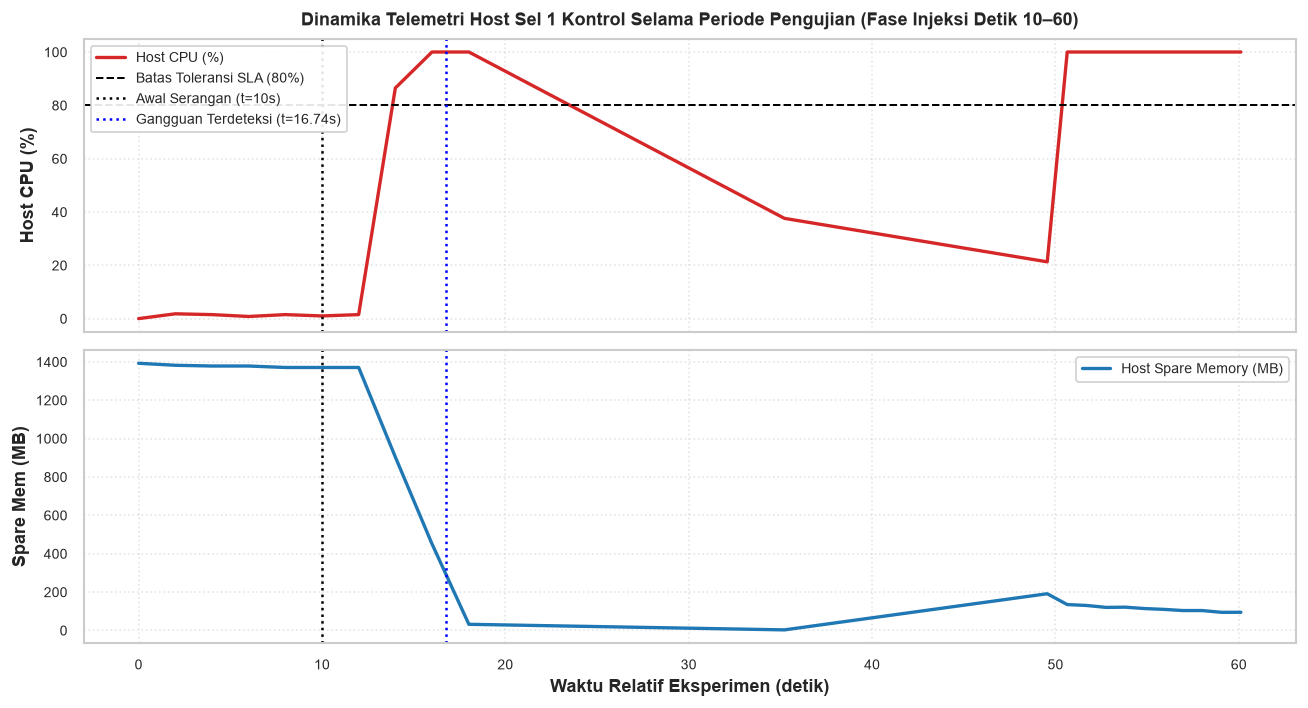

Temuan Kunci: Sesaat setelah t=10s, Host CPU melonjak mendekati 100% dan memori host terkuras drastis tanpa adanya isolasi cgroups.


In [58]:
# 2.3 Visualisasi Runtun Waktu Host Sel 1 Kontrol (Stacked Subplots Tanpa Dual-Axis)
ts_candidates = [target_dir / f"metrics_cell_01_rep_{r:02d}.csv" for r in range(1, 6)]
ts_file = next((f for f in ts_candidates if f.exists()), None)

if ts_file:
    df_ts1 = pd.read_csv(ts_file)
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
    
    # Subplot 1: Host CPU Utilization
    ax1.plot(df_ts1["elapsed_s"], df_ts1["host_cpu_pct"], color="#d62728", linewidth=2.0, label="Host CPU (%)")
    ax1.axhline(y=80.0, color="black", linestyle="--", linewidth=1.2, label="Batas Toleransi SLA (80%)")
    ax1.axvline(x=10.0, color="black", linestyle=":", linewidth=1.5, label="Awal Serangan (t=10s)")
    ax1.axvline(x=10.0 + mean_anomaly, color="blue", linestyle=":", linewidth=1.5, label=f"Gangguan Terdeteksi (t={10.0+mean_anomaly:.2f}s)")
    ax1.set_ylabel("Host CPU (%)", weight="bold")
    ax1.set_ylim(-5, 105)
    ax1.legend(loc="upper left", framealpha=0.9)
    ax1.set_title("Dinamika Telemetri Host Sel 1 Kontrol Selama Periode Pengujian (Fase Injeksi Detik 10–60)", weight="bold", pad=8)
    ax1.grid(True, linestyle=":", alpha=0.5)
    
    # Subplot 2: Host Spare Memory
    ax2.plot(df_ts1["elapsed_s"], df_ts1["host_spare_mem_mb"], color="#1f77b4", linewidth=2.0, label="Host Spare Memory (MB)")
    ax2.axvline(x=10.0, color="black", linestyle=":", linewidth=1.5)
    ax2.axvline(x=10.0 + mean_anomaly, color="blue", linestyle=":", linewidth=1.5)
    ax2.set_xlabel("Waktu Relatif Eksperimen (detik)", weight="bold")
    ax2.set_ylabel("Spare Mem (MB)", weight="bold")
    ax2.legend(loc="upper right", framealpha=0.9)
    ax2.grid(True, linestyle=":", alpha=0.5)
    
    plt.tight_layout()
    plt.show()
    print("Temuan Kunci: Sesaat setelah t=10s, Host CPU melonjak mendekati 100% dan memori host terkuras drastis tanpa adanya isolasi cgroups.")

#### 3. Kondisi Variabel Terikat Victim Container Selama Diserang pada ke-16 Konfigurasi
Mengevaluasi secara spesifik dinamika waktu-nyata performa layanan *Victim Container* (Latensi P95 dan Ketersediaan Layanan) saat menerima serangan beban kerja ekstrem dari *Aggressor Container* di seluruh 16 sel konfigurasi cgroups v2.

In [59]:
# 3.0 Ekstraksi Runtun Waktu Dinamika Victim Container dari Berkas JTL (80 Sesi)
print("Mengekstraksi dinamika runtun waktu Victim Container per detik dari berkas JTL...")
victim_dynamics = {}

for cell_id in range(1, 17):
    rep_dfs = []
    for rep in range(1, 6):
        jtl_p = target_dir / f"jmeter_cell_{cell_id:02d}_rep_{rep:02d}.jtl"
        if not jtl_p.exists():
            continue
        try:
            jtl_df = pd.read_csv(jtl_p)
            v_jtl = jtl_df[jtl_df["label"] == "Victim_Request"].copy()
            if v_jtl.empty:
                continue
            v_jtl["rel_s"] = (v_jtl["timeStamp"] - v_jtl["timeStamp"].min()) / 1000.0
            v_jtl["sec"] = v_jtl["rel_s"].astype(int)
            v_jtl = v_jtl[v_jtl["sec"] <= 60]
            
            sec_agg = v_jtl.groupby("sec").agg(
                lat_p95=("elapsed", lambda x: np.percentile(x, 95)),
                lat_mean=("elapsed", "mean"),
                rps=("elapsed", "count"),
                success_cnt=("success", lambda x: (x == True).sum()),
                fail_cnt=("success", lambda x: (x == False).sum()),
            ).reset_index()
            sec_agg["rep"] = rep
            rep_dfs.append(sec_agg)
        except Exception as e:
            pass
            
    if rep_dfs:
        comb_cell = pd.concat(rep_dfs, ignore_index=True)
        cell_summary = comb_cell.groupby("sec").agg(
            lat_p95_mean=("lat_p95", "mean"),
            lat_p95_std=("lat_p95", "std"),
            lat_p95_min=("lat_p95", "min"),
            lat_p95_max=("lat_p95", "max"),
            rps_mean=("rps", "mean"),
            success_mean=("success_cnt", "mean"),
            fail_mean=("fail_cnt", "mean"),
        ).reset_index()
        victim_dynamics[cell_id] = cell_summary

print(f"Ekstraksi tuntas: {len(victim_dynamics)} sel konfigurasi siap divisualisasikan.")

Mengekstraksi dinamika runtun waktu Victim Container per detik dari berkas JTL...
Ekstraksi tuntas: 16 sel konfigurasi siap divisualisasikan.


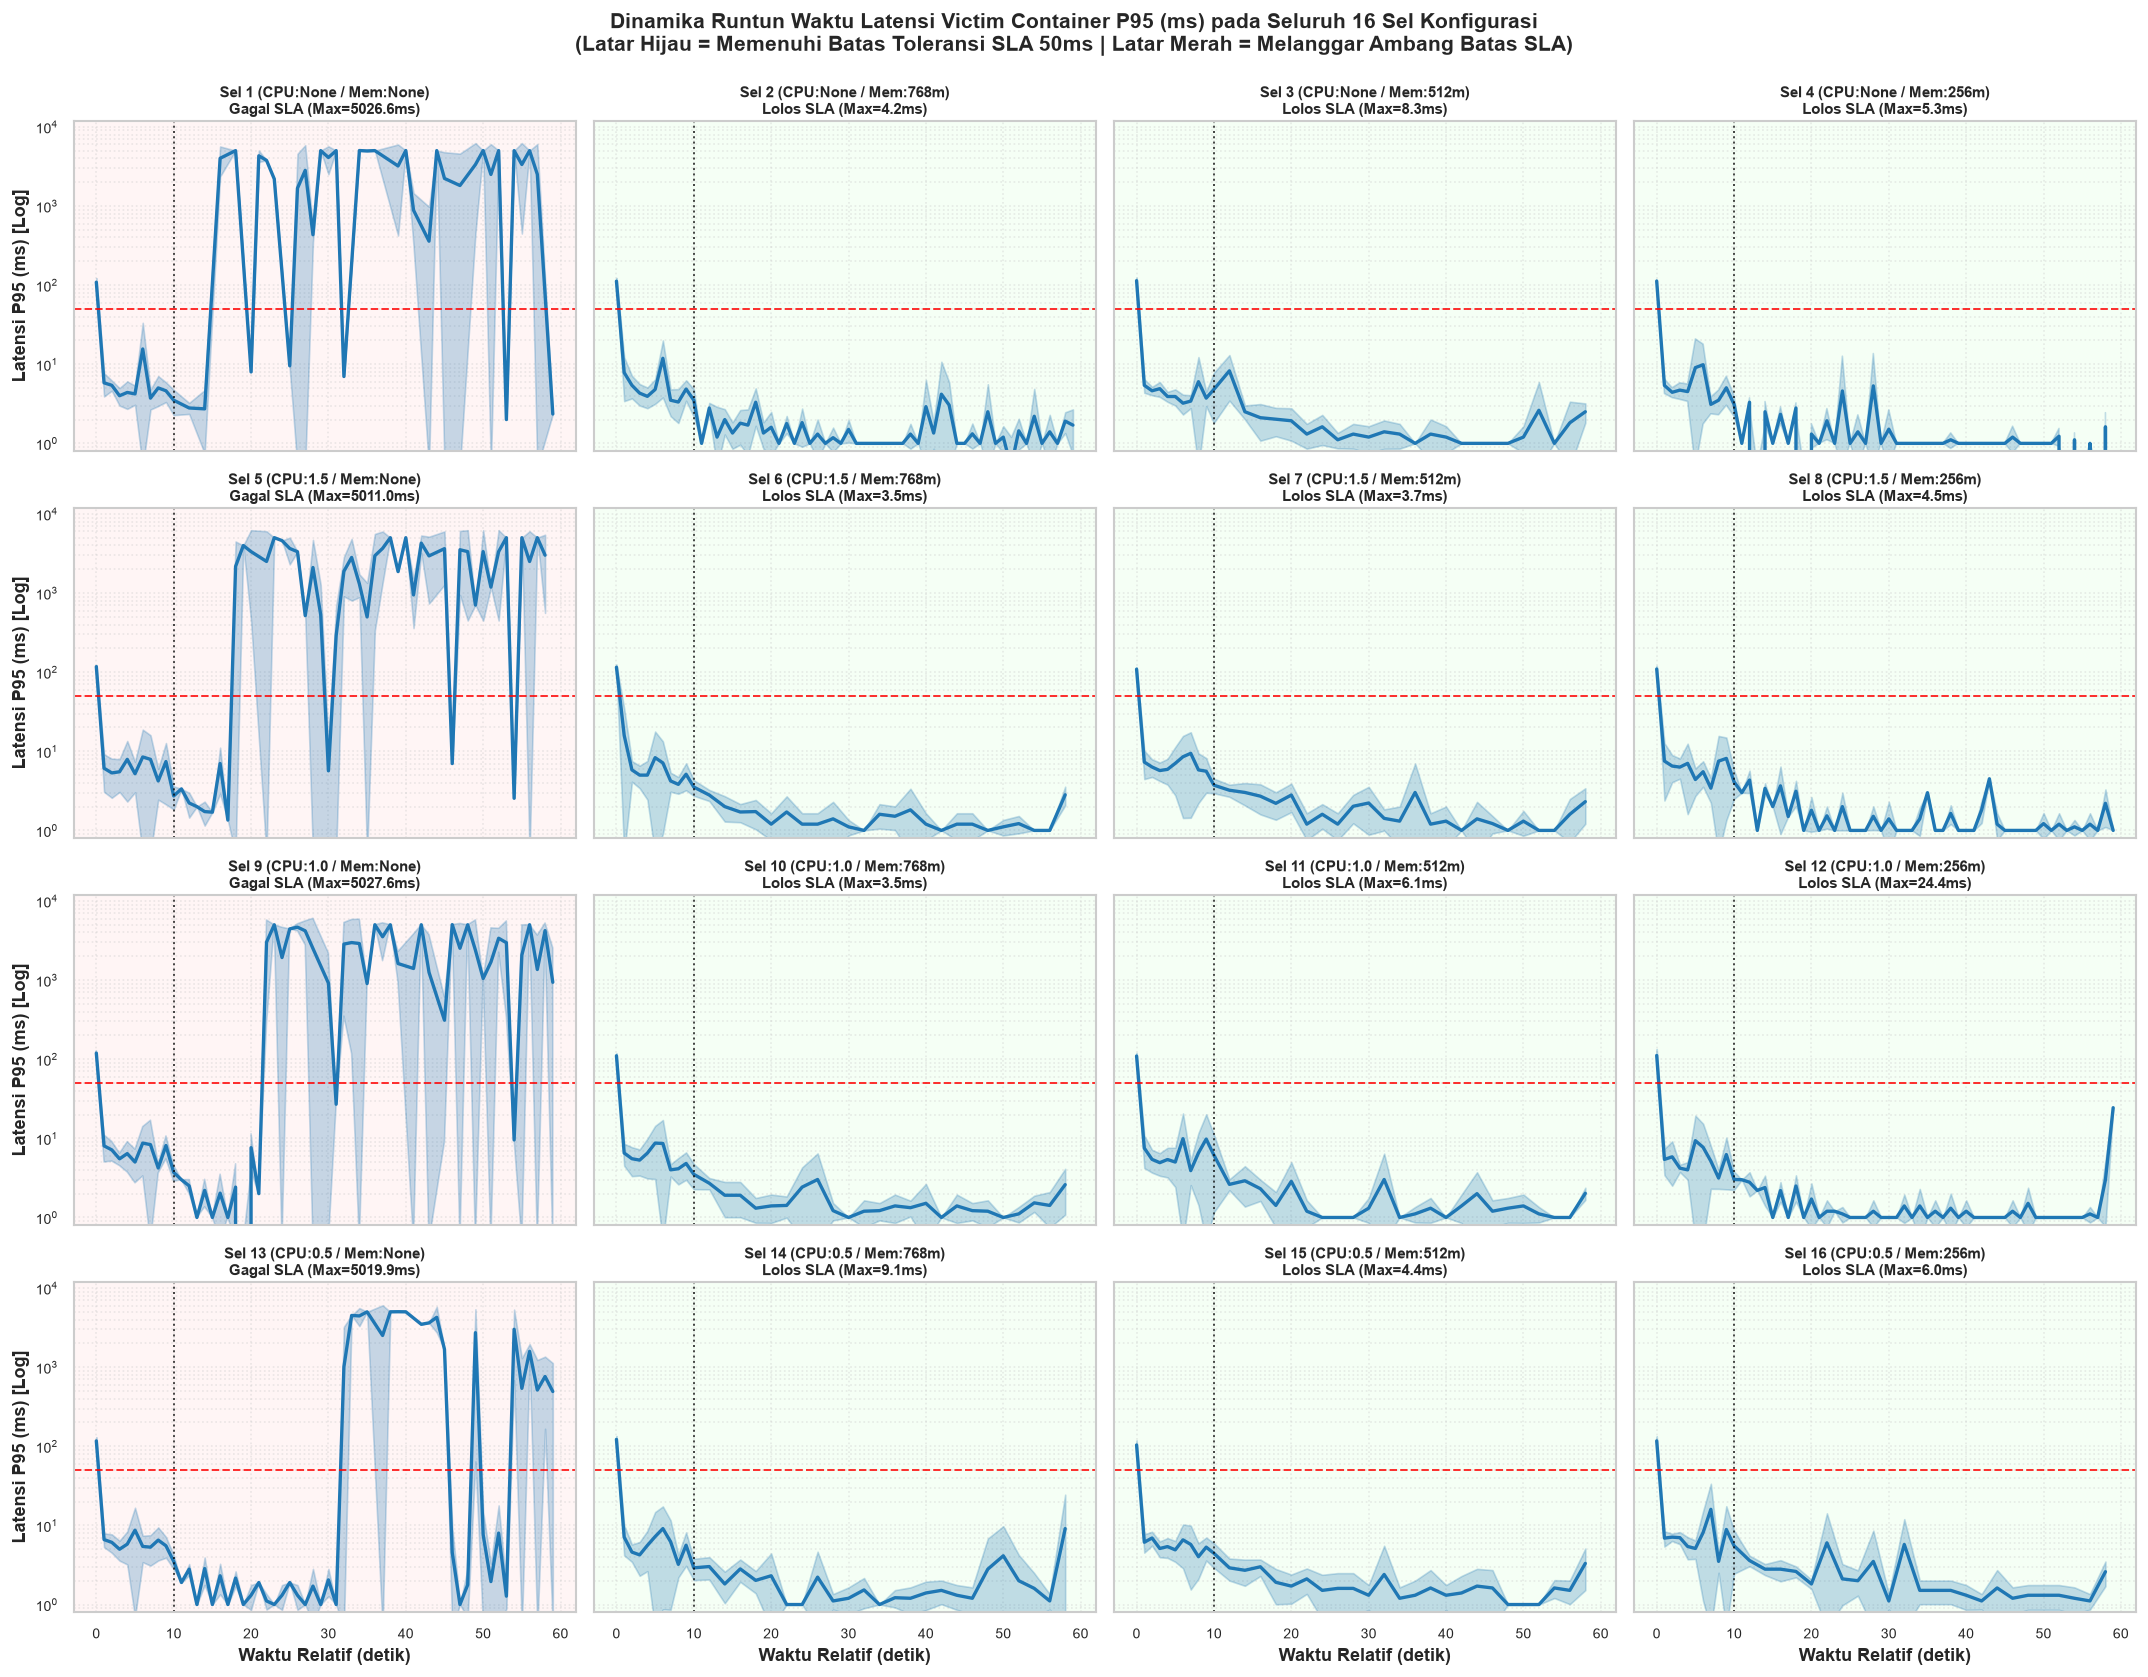

Temuan Kunci: Seluruh sel tanpa batas memori (kolom paling kiri: Sel 1, 5, 9, 13) mengalami lonjakan latensi ekstrem melanggar SLA 50ms,
sedangkan sel dengan batas memori (kolom 2–4) mempertahankan latensi stabil di kisaran ~2ms.


In [60]:
# 3.1 Visualisasi 1: Grid 4x4 Runtun Waktu Latensi Victim Container (Skala Logaritmik)
fig, axes = plt.subplots(4, 4, figsize=(18, 14), sharex=True, sharey=True)

cells_meta = {
    1: ('None', 'None'), 2: ('None', '768m'), 3: ('None', '512m'), 4: ('None', '256m'),
    5: ('1.5', 'None'), 6: ('1.5', '768m'), 7: ('1.5', '512m'), 8: ('1.5', '256m'),
    9: ('1.0', 'None'), 10: ('1.0', '768m'), 11: ('1.0', '512m'), 12: ('1.0', '256m'),
    13: ('0.5', 'None'), 14: ('0.5', '768m'), 15: ('0.5', '512m'), 16: ('0.5', '256m'),
}

for cell_id, (cpu, mem) in cells_meta.items():
    i = CPU_LEVELS.index(cpu)
    j = MEM_LEVELS.index(mem)
    ax = axes[i, j]
    
    max_p95 = np.nan
    if cell_id in victim_dynamics:
        c_df = victim_dynamics[cell_id]
        max_p95 = c_df[c_df["sec"] >= 10]["lat_p95_mean"].max()
        
        ax.plot(c_df["sec"], c_df["lat_p95_mean"], color="#1f77b4", linewidth=2.0, label="Latensi P95")
        std_clean = c_df["lat_p95_std"].fillna(0)
        ax.fill_between(
            c_df["sec"],
            np.maximum(0.5, c_df["lat_p95_mean"] - std_clean),
            c_df["lat_p95_mean"] + std_clean,
            color="#1f77b4", alpha=0.25
        )
        
    # Garis SLA 50 ms & Awal Serangan t=10s
    ax.axhline(y=50.0, color="red", linestyle="--", linewidth=1.2, alpha=0.8, label="SLA (50ms)")
    ax.axvline(x=10.0, color="black", linestyle=":", linewidth=1.2, alpha=0.7, label="Injeksi (t=10s)")
    
    # Skala logaritmik agar latensi 2ms dan 5000ms dapat teramati jelas secara proporsional
    ax.set_yscale("log")
    ax.set_ylim(0.8, 12000)
    
    is_compliant = pd.notna(max_p95) and (max_p95 <= SLA_LATENCY_MAX_MS)
    ax.set_facecolor("#f5fff5" if is_compliant else "#fff5f5")
    
    status_txt = f"Lolos SLA (Max={max_p95:.1f}ms)" if is_compliant else f"Gagal SLA (Max={max_p95:.1f}ms)"
    ax.set_title(f"Sel {cell_id} (CPU:{cpu} / Mem:{mem})\n{status_txt}", fontsize=9.2, weight="bold", pad=4)
    ax.grid(True, which="both", linestyle=":", alpha=0.4)

for j in range(4):
    axes[3, j].set_xlabel("Waktu Relatif (detik)", fontsize=10.5, weight="bold")
for i in range(4):
    axes[i, 0].set_ylabel("Latensi P95 (ms) [Log]", fontsize=10.5, weight="bold")

fig.suptitle("Dinamika Runtun Waktu Latensi Victim Container P95 (ms) pada Seluruh 16 Sel Konfigurasi\n(Latar Hijau = Memenuhi Batas Toleransi SLA 50ms | Latar Merah = Melanggar Ambang Batas SLA)", fontsize=12.5, weight="bold", y=0.995)
plt.tight_layout()
fig.subplots_adjust(top=0.93)
plt.show()
print("Temuan Kunci: Seluruh sel tanpa batas memori (kolom paling kiri: Sel 1, 5, 9, 13) mengalami lonjakan latensi ekstrem melanggar SLA 50ms,")
print("sedangkan sel dengan batas memori (kolom 2–4) mempertahankan latensi stabil di kisaran ~2ms.")

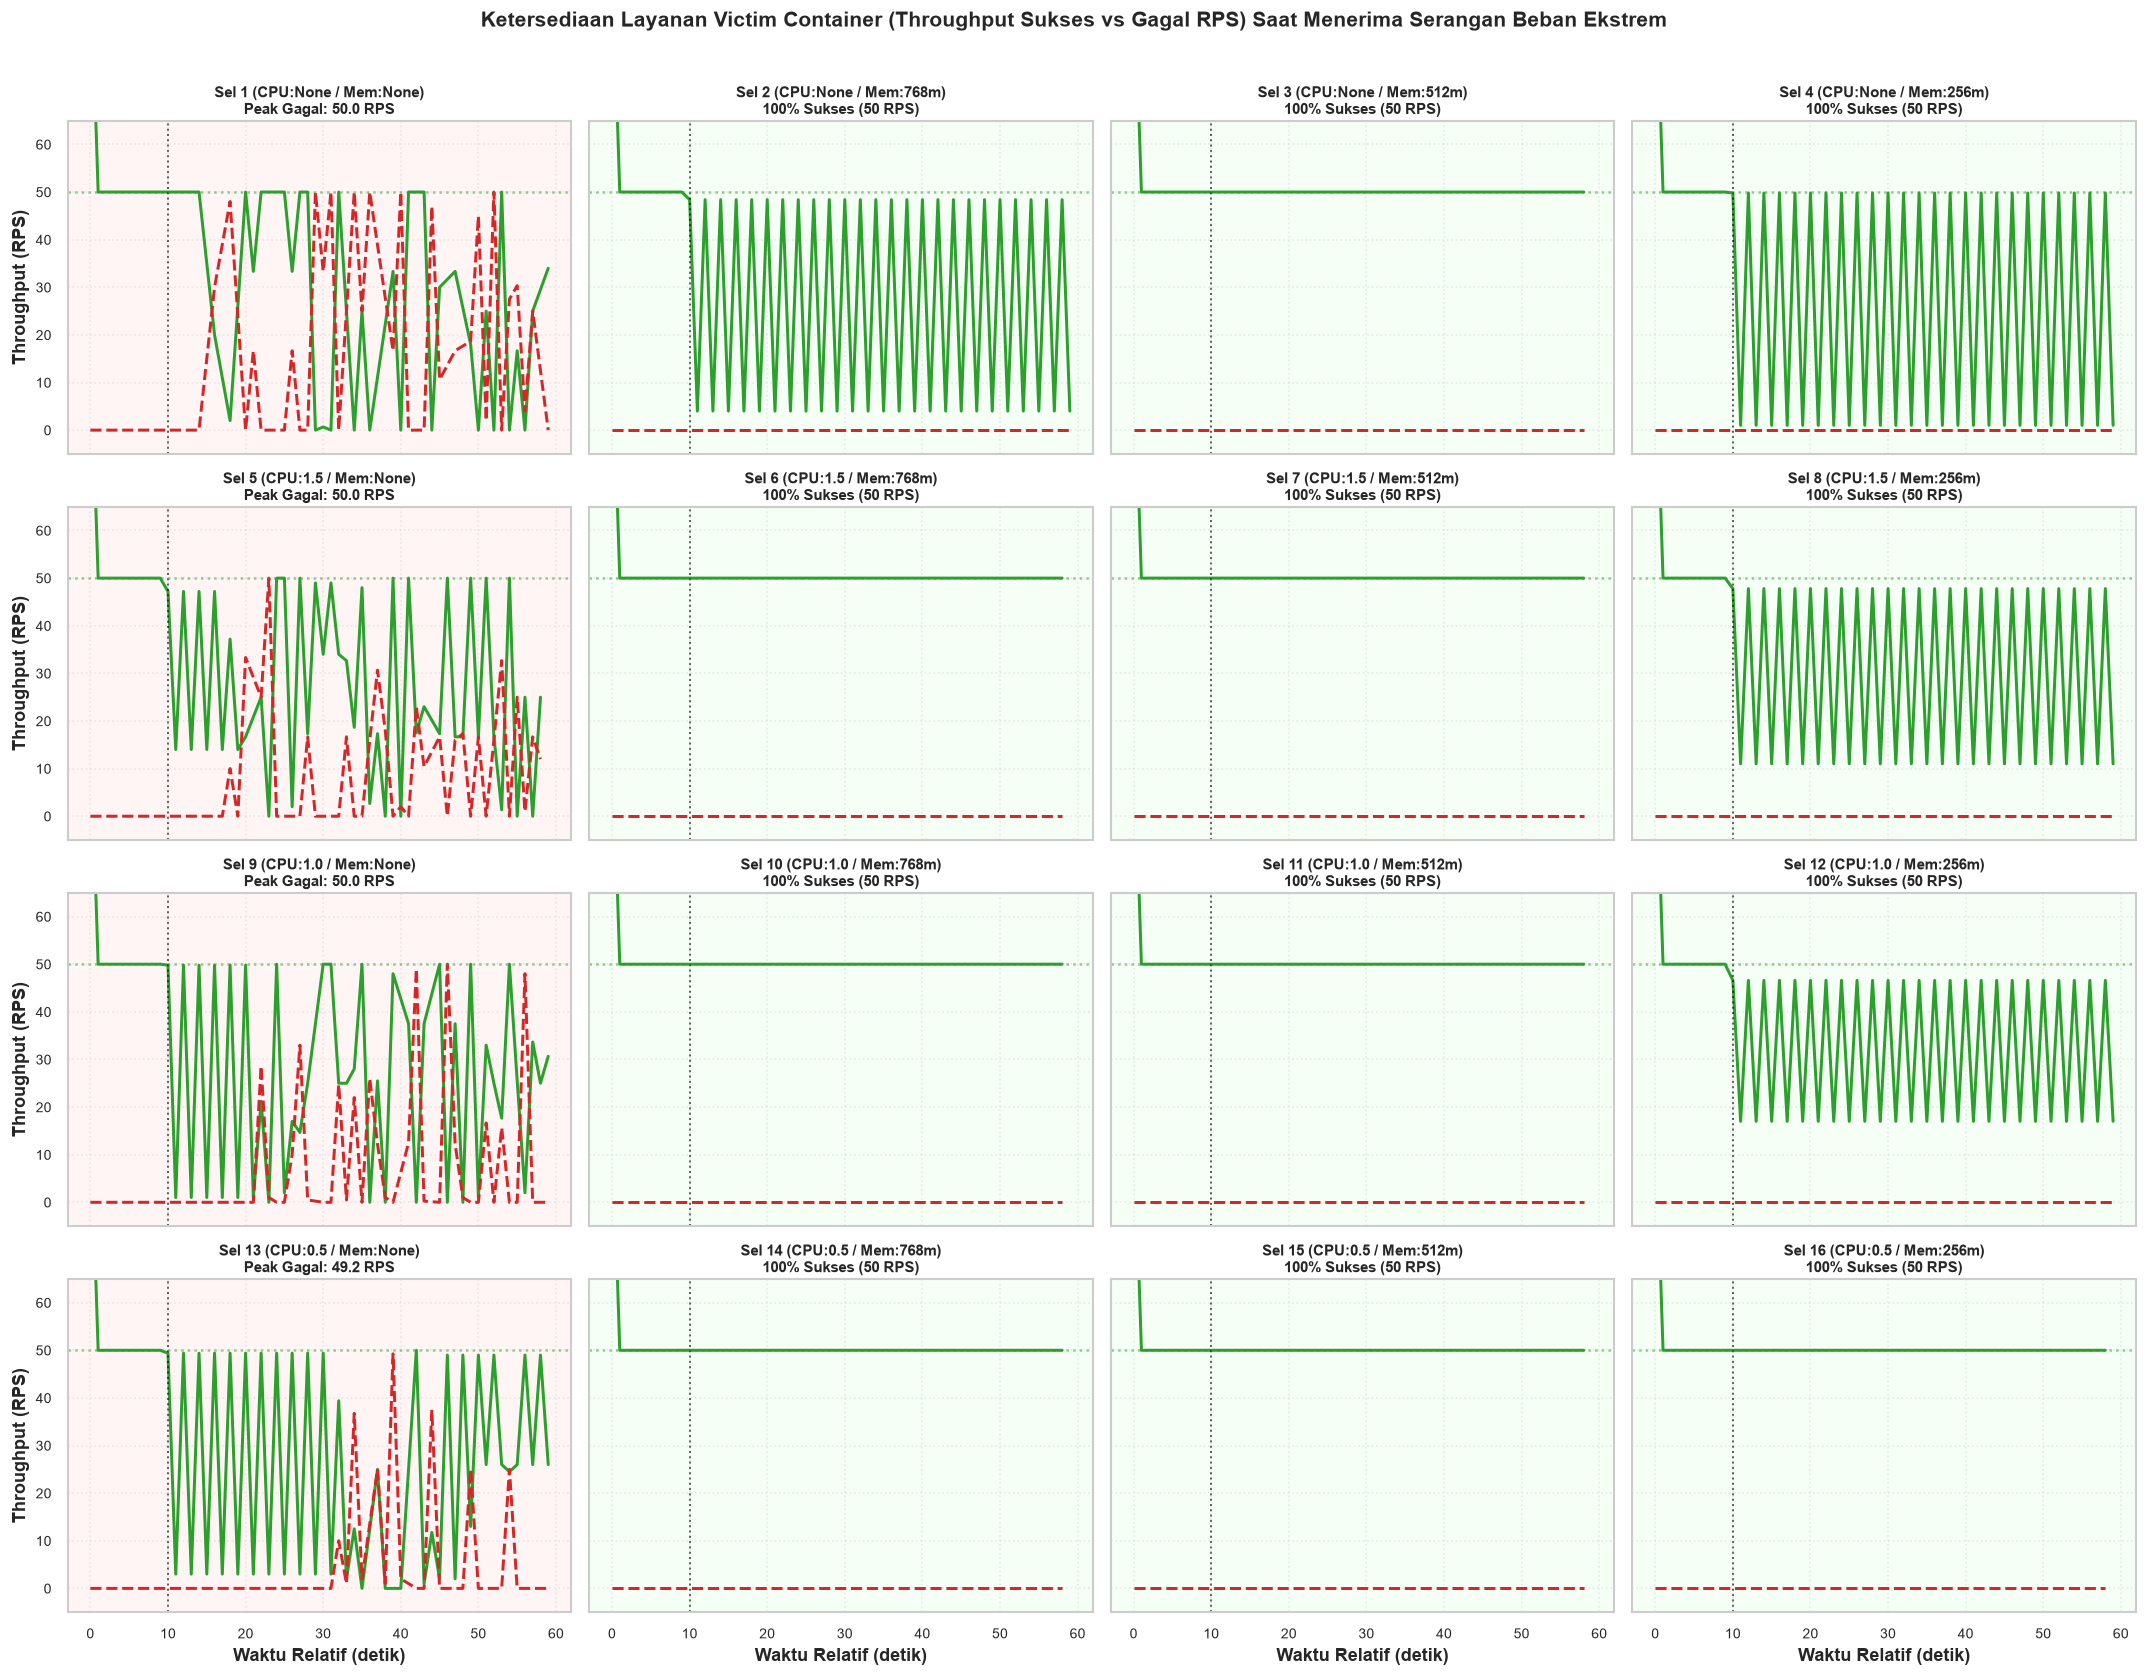

Temuan Kunci: Ketiadaan limit memori memicu kegagalan transaksi HTTP (garis merah putus-putus) dan penurunan laju transaksi sukses.


In [61]:
# 3.2 Visualisasi 2: Grid 4x4 Ketersediaan Layanan (Throughput Sukses vs Gagal RPS)
fig, axes = plt.subplots(4, 4, figsize=(18, 14), sharex=True, sharey=True)

for cell_id, (cpu, mem) in cells_meta.items():
    i = CPU_LEVELS.index(cpu)
    j = MEM_LEVELS.index(mem)
    ax = axes[i, j]
    
    fail_peak = 0.0
    if cell_id in victim_dynamics:
        c_df = victim_dynamics[cell_id]
        fail_peak = c_df[c_df["sec"] >= 10]["fail_mean"].max()
        ax.plot(c_df["sec"], c_df["success_mean"], color="#2ca02c", linewidth=1.8, label="Sukses (200 OK)")
        ax.plot(c_df["sec"], c_df["fail_mean"], color="#d62728", linewidth=1.8, linestyle="--", label="Gagal (Error/Timeout)")
        
    ax.axvline(x=10.0, color="black", linestyle=":", linewidth=1.2, alpha=0.6)
    ax.axhline(y=50.0, color="#2ca02c", linestyle=":", alpha=0.5, label="Target 50 RPS")
    
    has_failures = fail_peak > 0.5
    ax.set_facecolor("#fff5f5" if has_failures else "#f5fff5")
    tag = f"Peak Gagal: {fail_peak:.1f} RPS" if has_failures else "100% Sukses (50 RPS)"
    
    ax.set_title(f"Sel {cell_id} (CPU:{cpu} / Mem:{mem})\n{tag}", fontsize=9.2, weight="bold", pad=4)
    ax.set_ylim(-5, 65)
    ax.grid(True, linestyle=":", alpha=0.4)

for j in range(4):
    axes[3, j].set_xlabel("Waktu Relatif (detik)", fontsize=10.5, weight="bold")
for i in range(4):
    axes[i, 0].set_ylabel("Throughput (RPS)", fontsize=10.5, weight="bold")

fig.suptitle("Ketersediaan Layanan Victim Container (Throughput Sukses vs Gagal RPS) Saat Menerima Serangan Beban Ekstrem", fontsize=12.5, weight="bold", y=0.995)
plt.tight_layout()
fig.subplots_adjust(top=0.93)
plt.show()
print("Temuan Kunci: Ketiadaan limit memori memicu kegagalan transaksi HTTP (garis merah putus-putus) dan penurunan laju transaksi sukses.")

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_33628\2033390277.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_33628\2033390277.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


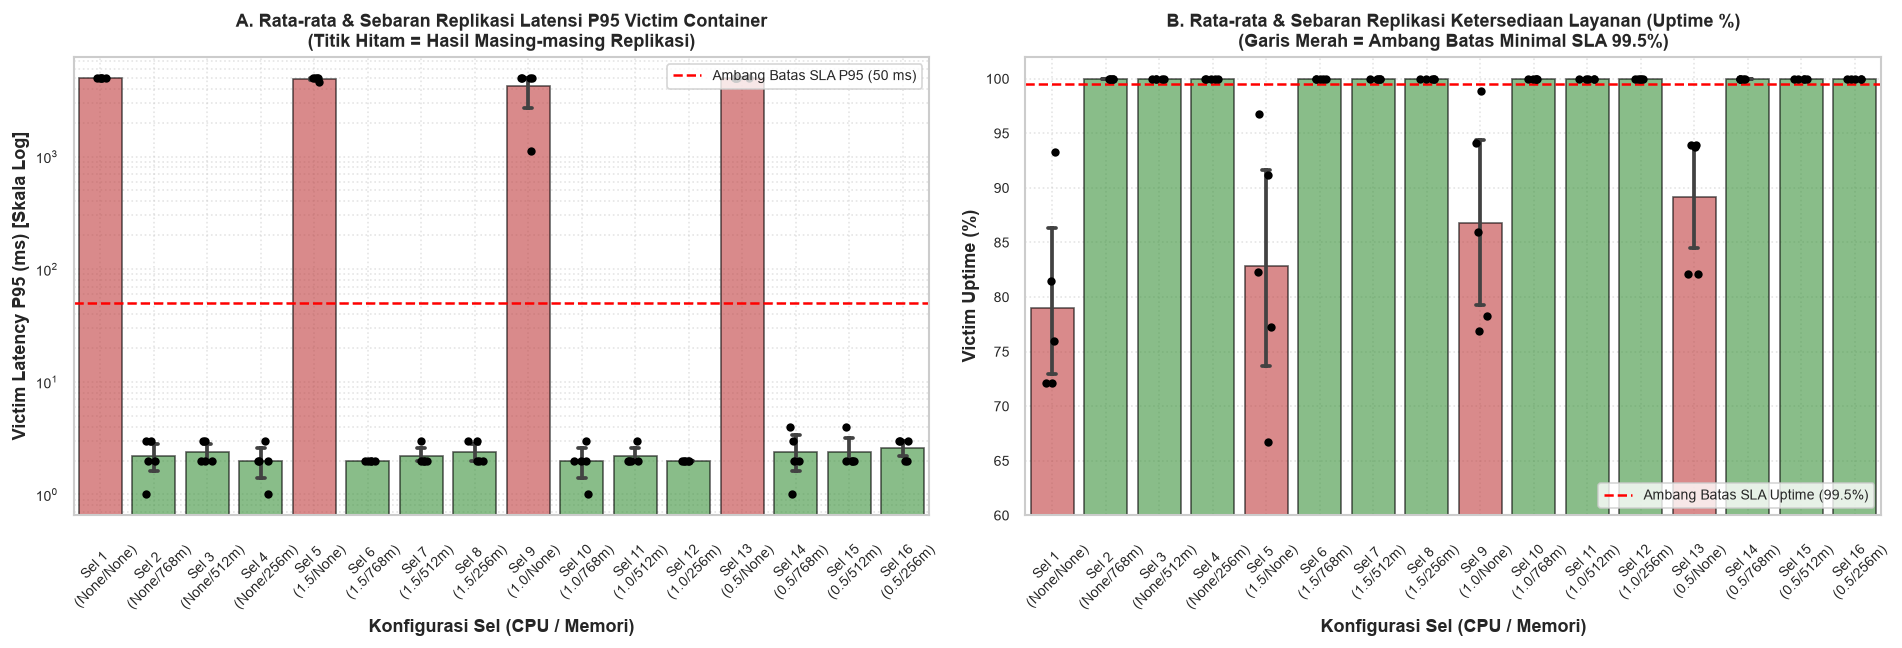

Cara Baca: Titik hitam mewakili hasil 5 replikasi acak. Seluruh konfigurasi terisolasi memori berada aman di bawah garis SLA 50ms dan di atas 99.5% Uptime.


In [62]:
# 3.3 Visualisasi 3: Bar Chart Komparasi dengan Sebaran Titik Replikasi (Strip Plot)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.5))

# Subplot 1: Victim Latency P95 (Log Scale + Sebaran Titik 5 Replikasi)
sns.barplot(
    data=df_sessions,
    x="cfg_label",
    y="victim_lat_p95_ms",
    palette=["#d62728" if cid in [1, 5, 9, 13] else "#2ca02c" for cid in range(1, 17)],
    alpha=0.6,
    edgecolor="black",
    ax=ax1,
    capsize=0.15,
)
sns.stripplot(
    data=df_sessions,
    x="cfg_label",
    y="victim_lat_p95_ms",
    color="black",
    size=5,
    jitter=0.15,
    ax=ax1,
)
ax1.axhline(y=50.0, color="red", linestyle="--", linewidth=1.5, label="Ambang Batas SLA P95 (50 ms)")
ax1.set_yscale("log")
ax1.set_xlabel("Konfigurasi Sel (CPU / Memori)", weight="bold")
ax1.set_ylabel("Victim Latency P95 (ms) [Skala Log]", weight="bold")
ax1.set_title("A. Rata-rata & Sebaran Replikasi Latensi P95 Victim Container\n(Titik Hitam = Hasil Masing-masing Replikasi)", weight="bold")
ax1.tick_params(axis="x", rotation=45)
ax1.legend(loc="upper right")
ax1.grid(True, which="both", linestyle=":", alpha=0.5)

# Subplot 2: Victim Uptime (%)
sns.barplot(
    data=df_sessions,
    x="cfg_label",
    y="victim_uptime_pct",
    palette=["#d62728" if cid in [1, 5, 9, 13] else "#2ca02c" for cid in range(1, 17)],
    alpha=0.6,
    edgecolor="black",
    ax=ax2,
    capsize=0.15,
)
sns.stripplot(
    data=df_sessions,
    x="cfg_label",
    y="victim_uptime_pct",
    color="black",
    size=5,
    jitter=0.15,
    ax=ax2,
)
ax2.axhline(y=99.5, color="red", linestyle="--", linewidth=1.5, label="Ambang Batas SLA Uptime (99.5%)")
ax2.set_xlabel("Konfigurasi Sel (CPU / Memori)", weight="bold")
ax2.set_ylabel("Victim Uptime (%)", weight="bold")
ax2.set_ylim(60, 102)
ax2.set_title("B. Rata-rata & Sebaran Replikasi Ketersediaan Layanan (Uptime %)\n(Garis Merah = Ambang Batas Minimal SLA 99.5%)", weight="bold")
ax2.tick_params(axis="x", rotation=45)
ax2.legend(loc="lower right")
ax2.grid(True, linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()
print("Cara Baca: Titik hitam mewakili hasil 5 replikasi acak. Seluruh konfigurasi terisolasi memori berada aman di bawah garis SLA 50ms dan di atas 99.5% Uptime.")

#### 4. Rumusan Masalah 2: Evaluasi Efektivitas 16 Sel Konfigurasi Cgroups & Klasifikasi 3-Tier
Memetakan efektivitas isolasi berdasarkan keterpenuhan kriteria SLA (Uptime $\ge 99.5\%$, Latensi P95 $\le 50.0$ ms, Host CPU $\le 80.0\%$) pada sekurang-kurangnya 4 dari 5 replikasi ($\ge 80\%$):

In [63]:
# 4.1 Evaluasi Konsistensi Replikasi & Penentuan Klasifikasi 3-Tier
cell_groups = df_sessions.groupby("cell_id")

t343_summary = []
for cell_id, grp in cell_groups:
    cpus = grp["cpus"].iloc[0]
    memory = grp["memory"].iloc[0]
    cell_name = grp["cell_name"].iloc[0]
    
    n_reps = len(grp)
    pass_count = grp["session_pass"].sum()
    consistency_pct = (pass_count / n_reps) * 100.0
    oom_count = grp["oom_killed"].sum()
    
    cpu_mean = grp["host_cpu_inj_pct"].mean()
    cpu_std = grp["host_cpu_inj_pct"].std()
    mem_mean = grp["host_spare_mem_inj_mb"].mean()
    mem_std = grp["host_spare_mem_inj_mb"].std()
    lat_mean = grp["victim_lat_p95_ms"].mean()
    lat_std = grp["victim_lat_p95_ms"].std()
    uptime_mean = grp["victim_uptime_pct"].mean()
    uptime_std = grp["victim_uptime_pct"].std()
    throt_mean = grp["throttled_sec"].mean()
    
    # Klasifikasi 3-Tier Berdasarkan Standar Evaluasi Bab 3.4.5
    is_effective = pass_count >= 4
    if not is_effective:
        status_tier = "Tier 3: Tidak Efektif"
        tier_code = 0
    else:
        if oom_count >= 4:
            status_tier = "Tier 2: Efektif (OOM Kill)"
            tier_code = 1
        else:
            status_tier = "Tier 1: Efektif (Optimal)"
            tier_code = 2
            
    t343_summary.append({
        "Sel ID": cell_id,
        "Nama Sel": cell_name,
        "Limit CPU": cpus,
        "Limit Memori": memory,
        "Host CPU (%)": f"{cpu_mean:.1f} ± {cpu_std:.1f}" if pd.notna(cpu_mean) else "N/A",
        "Host Spare Mem (MB)": f"{mem_mean:.0f} ± {mem_std:.0f}" if pd.notna(mem_mean) else "N/A",
        "Victim Latency P95 (ms)": f"{lat_mean:.1f} ± {lat_std:.1f}",
        "Victim Uptime (%)": f"{uptime_mean:.2f} ± {uptime_std:.2f}",
        "Throttling (s)": f"{throt_mean:.2f}",
        "OOM Kill (Replikasi)": f"{oom_count}/{n_reps}",
        "Konsistensi Lolos": f"{pass_count}/{n_reps} ({consistency_pct:.0f}%)",
        "Klasifikasi 3-Tier": status_tier,
        "Tier Code": tier_code,
        "raw_cpu_mean": cpu_mean,
        "raw_mem_mean": mem_mean,
        "raw_lat_mean": lat_mean,
        "raw_uptime_mean": uptime_mean,
        "raw_throt_mean": throt_mean,
    })

df_t343 = pd.DataFrame(t343_summary)
tier1_cells = df_t343[df_t343["Tier Code"] == 2]["Sel ID"].tolist()
tier2_cells = df_t343[df_t343["Tier Code"] == 1]["Sel ID"].tolist()
tier3_cells = df_t343[df_t343["Tier Code"] == 0]["Sel ID"].tolist()

print("Tabel 3.4.3 Rekapitulasi Efektivitas 16 Sel Konfigurasi (80 Sesi Eksperimen):")
try:
    display(df_t343[["Sel ID", "Nama Sel", "Limit CPU", "Limit Memori", "Host CPU (%)", "Host Spare Mem (MB)", "Victim Latency P95 (ms)", "Victim Uptime (%)", "Throttling (s)", "OOM Kill (Replikasi)", "Konsistensi Lolos", "Klasifikasi 3-Tier"]])
except NameError:
    print(df_t343[["Sel ID", "Nama Sel", "Limit CPU", "Limit Memori", "Host CPU (%)", "Host Spare Mem (MB)", "Victim Latency P95 (ms)", "Victim Uptime (%)", "Throttling (s)", "OOM Kill (Replikasi)", "Konsistensi Lolos", "Klasifikasi 3-Tier"]].to_string())

print(f"Distribusi Status: Tier 1 (Efektif Optimal) = {len(tier1_cells)} sel | Tier 2 (Efektif OOM Kill) = {len(tier2_cells)} sel | Tier 3 (Tidak Efektif) = {len(tier3_cells)} sel.")

Tabel 3.4.3 Rekapitulasi Efektivitas 16 Sel Konfigurasi (80 Sesi Eksperimen):


,Sel ID,Nama Sel,Limit CPU,Limit Memori,Host CPU (%),Host Spare Mem (MB),Victim Latency P95 (ms),Victim Uptime (%),Throttling (s),OOM Kill (Replikasi),Konsistensi Lolos,Klasifikasi 3-Tier
0,1,Sel 1 (Kontrol),None,None,79.3 ± nan,3 ± nan,5014.2 ± 5.3,79.00 ± 8.85,0.00,0/5,0/5 (0%),Tier 3: Tidak Efektif
1,2,Sel 2,None,768m,38.4 ± 4.0,734 ± 8,2.2 ± 0.8,100.00 ± 0.00,0.00,5/5,5/5 (100%),Tier 2: Efektif (OOM Kill)
2,3,Sel 3,None,512m,26.6 ± 7.8,993 ± 5,2.4 ± 0.5,100.00 ± 0.00,0.00,5/5,5/5 (100%),Tier 2: Efektif (OOM Kill)
3,4,Sel 4,None,256m,22.8 ± 4.0,1230 ± 20,2.0 ± 0.7,100.00 ± 0.00,0.00,5/5,5/5 (100%),Tier 2: Efektif (OOM Kill)
4,5,Sel 5,1.5,None,60.6 ± nan,0 ± nan,4929.0 ± 182.3,82.84 ± 11.79,2.02,0/5,0/5 (0%),Tier 3: Tidak Efektif
5,6,Sel 6,1.5,768m,34.8 ± 3.1,740 ± 7,2.0 ± 0.0,100.00 ± 0.00,8.42,5/5,5/5 (100%),Tier 2: Efektif (OOM Kill)
6,7,Sel 7,1.5,512m,23.7 ± 7.0,991 ± 7,2.2 ± 0.4,100.00 ± 0.00,4.91,5/5,5/5 (100%),Tier 2: Efektif (OOM Kill)
7,8,Sel 8,1.5,256m,21.9 ± 5.0,1231 ± 7,2.4 ± 0.5,100.00 ± 0.00,3.60,5/5,5/5 (100%),Tier 2: Efektif (OOM Kill)
8,9,Sel 9,1.0,None,38.2 ± 6.4,40 ± 45,4235.4 ± 1737.1,86.80 ± 9.62,18.44,2/5,0/5 (0%),Tier 3: Tidak Efektif
9,10,Sel 10,1.0,768m,33.3 ± 4.9,735 ± 7,2.0 ± 0.7,100.00 ± 0.00,26.97,5/5,5/5 (100%),Tier 2: Efektif (OOM Kill)


Distribusi Status: Tier 1 (Efektif Optimal) = 0 sel | Tier 2 (Efektif OOM Kill) = 12 sel | Tier 3 (Tidak Efektif) = 4 sel.


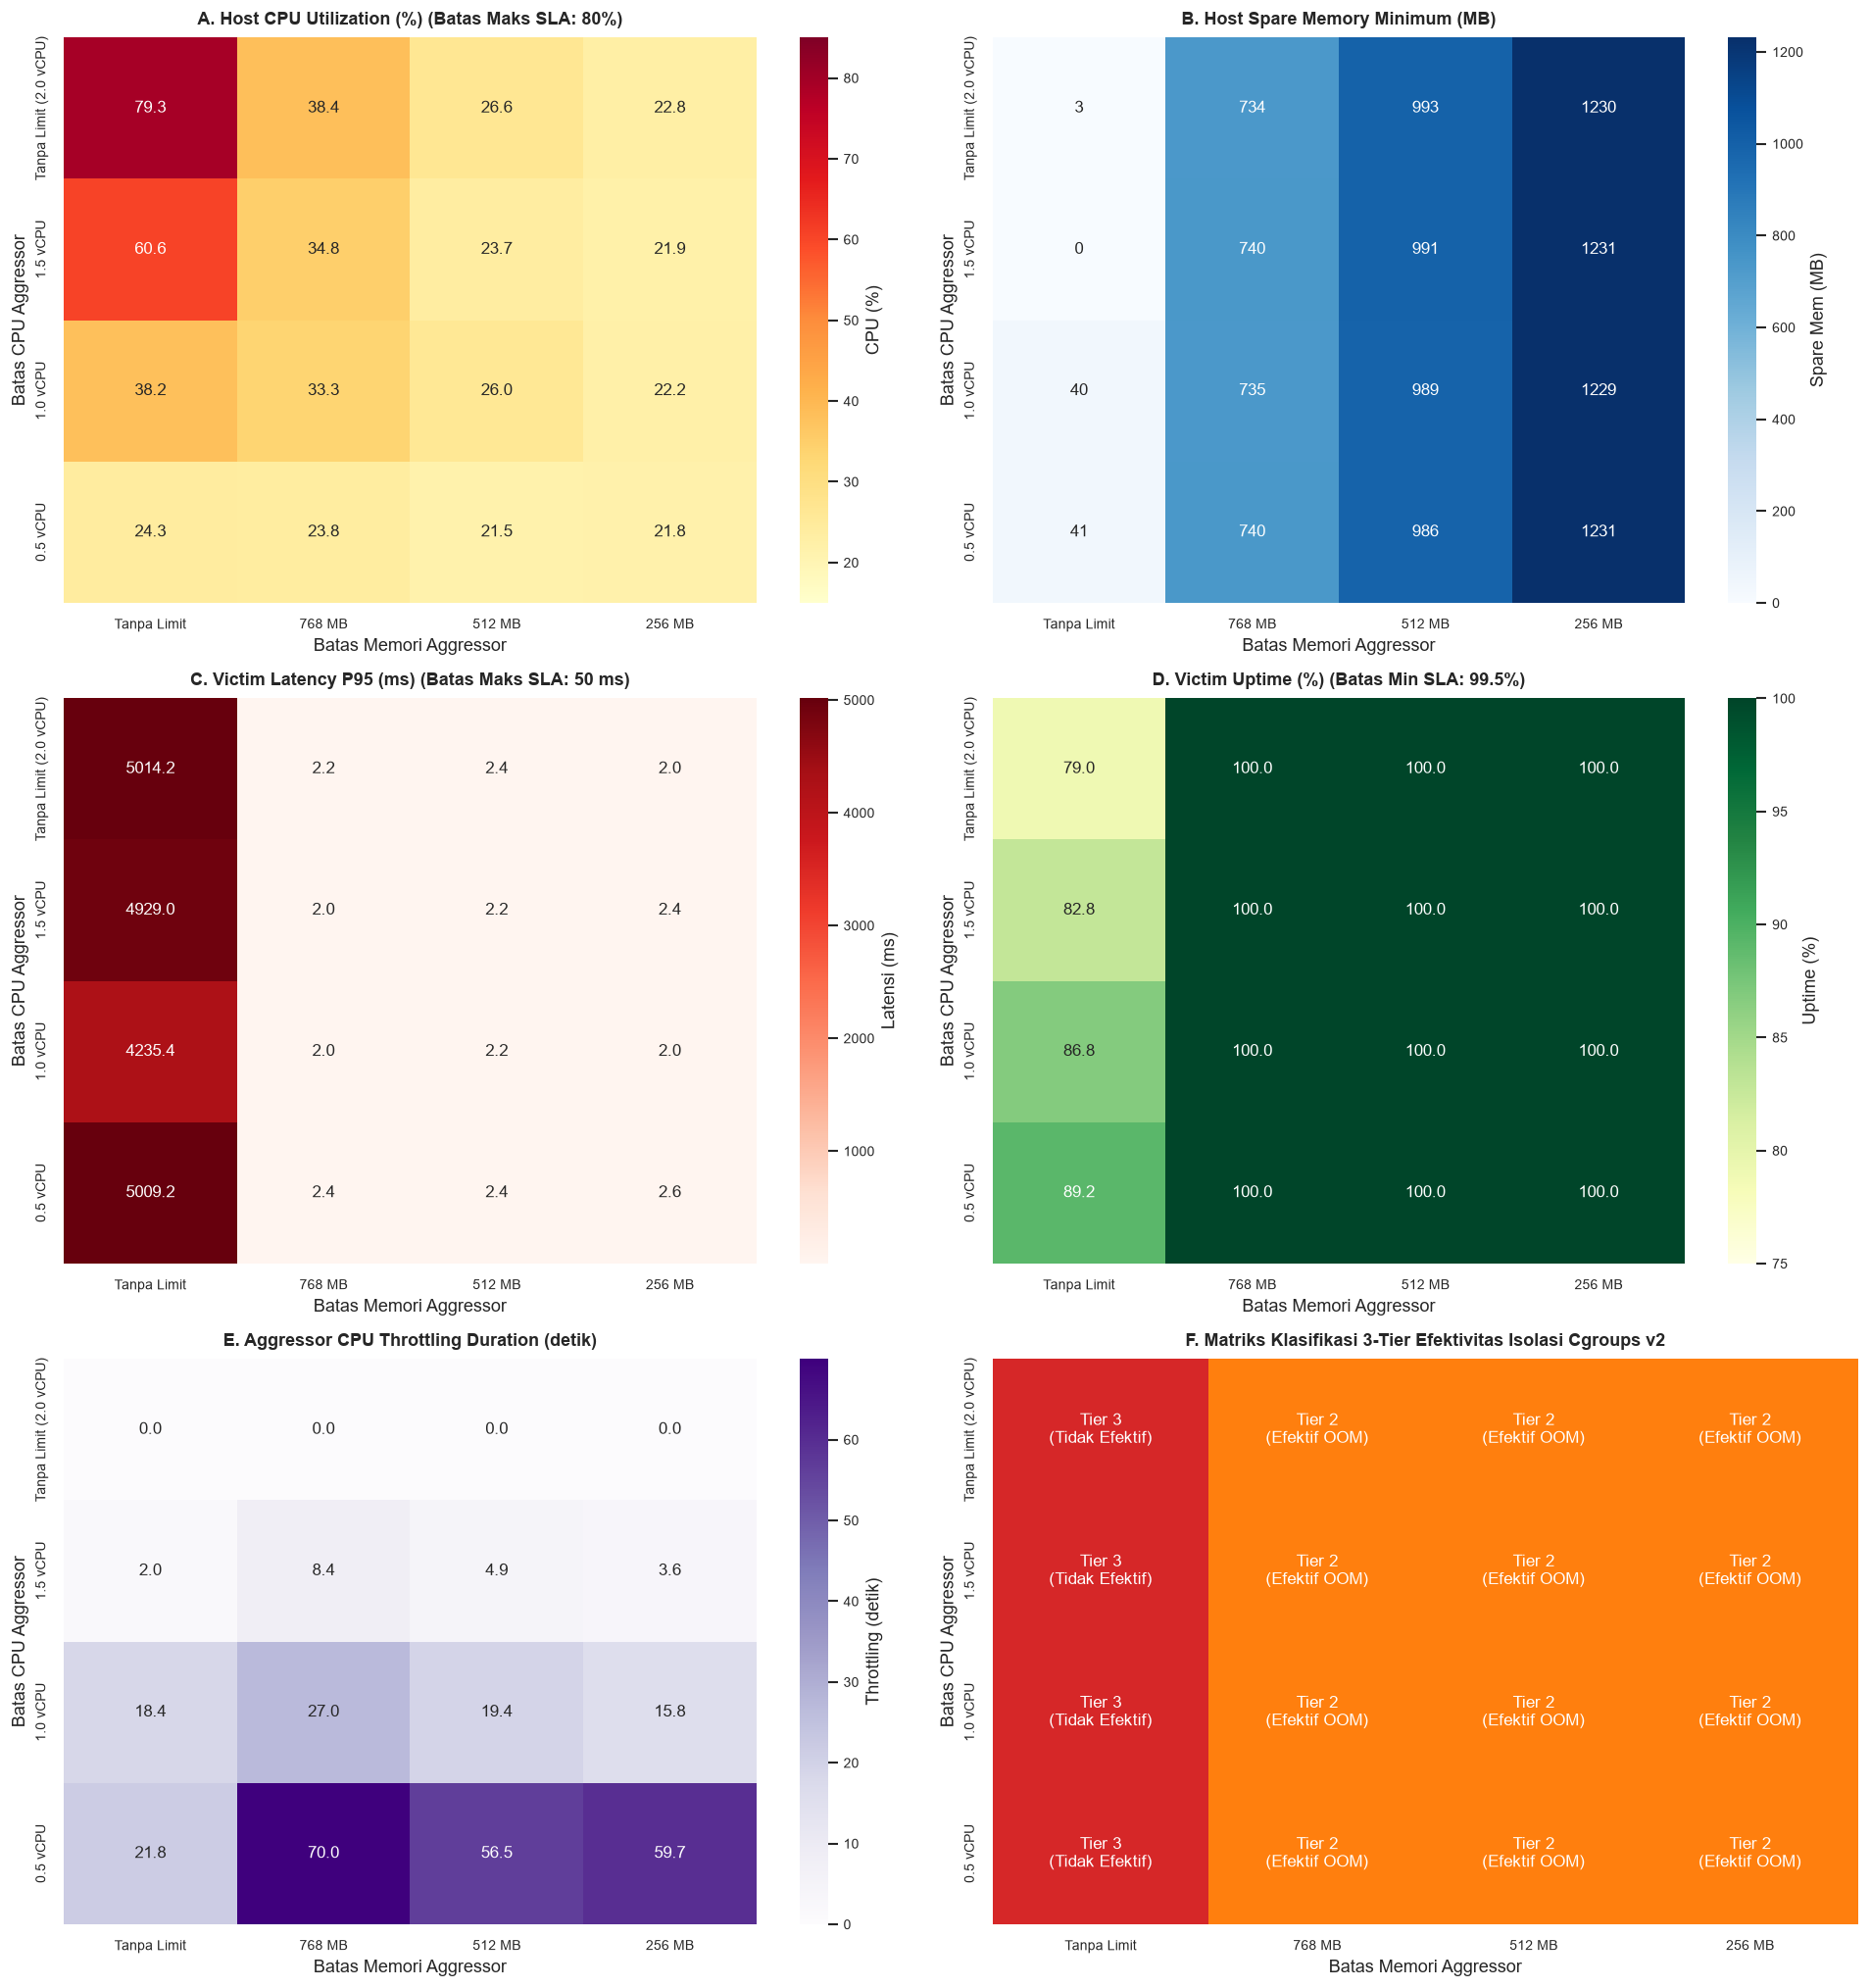

Cara Baca: Panel F memetakan status akhir isolasi. Seluruh sel berlimit memori terklasifikasi ke Tier 2 (Oranye),
karena intensitas beban memory flood memicu terminasi OOM Killer untuk melindungi stabilitas host dan victim container.


In [64]:
# 4.2 Visualisasi Heatmap Grid 4x4 Faktorial Penuh (6 Metrik Utama)
def build_grid_matrix(df: pd.DataFrame, metric_col: str) -> np.ndarray:
    mat = np.zeros((4, 4))
    for i, c in enumerate(CPU_LEVELS):
        for j, m in enumerate(MEM_LEVELS):
            sub = df[(df["Limit CPU"] == c) & (df["Limit Memori"] == m)]
            if not sub.empty:
                mat[i, j] = sub.iloc[0][metric_col]
            else:
                mat[i, j] = np.nan
    return mat

fig, axes = plt.subplots(3, 2, figsize=(16, 17))

# 1. Host CPU Utilization
g_cpu = build_grid_matrix(df_t343, "raw_cpu_mean")
sns.heatmap(g_cpu, annot=True, fmt=".1f", cmap="YlOrRd", xticklabels=MEM_LABELS, yticklabels=CPU_LABELS, cbar_kws={"label": "CPU (%)"}, ax=axes[0, 0], vmin=15, vmax=85)
axes[0, 0].set_title("A. Host CPU Utilization (%) (Batas Maks SLA: 80%)", fontsize=10.5, weight="bold", pad=8)
axes[0, 0].set_xlabel("Batas Memori Aggressor")
axes[0, 0].set_ylabel("Batas CPU Aggressor")

# 2. Host Spare Memory
g_mem = build_grid_matrix(df_t343, "raw_mem_mean")
sns.heatmap(g_mem, annot=True, fmt=".0f", cmap="Blues", xticklabels=MEM_LABELS, yticklabels=CPU_LABELS, cbar_kws={"label": "Spare Mem (MB)"}, ax=axes[0, 1])
axes[0, 1].set_title("B. Host Spare Memory Minimum (MB)", fontsize=10.5, weight="bold", pad=8)
axes[0, 1].set_xlabel("Batas Memori Aggressor")
axes[0, 1].set_ylabel("Batas CPU Aggressor")

# 3. Victim Latency P95 (ms)
g_lat = build_grid_matrix(df_t343, "raw_lat_mean")
sns.heatmap(g_lat, annot=True, fmt=".1f", cmap="Reds", xticklabels=MEM_LABELS, yticklabels=CPU_LABELS, cbar_kws={"label": "Latensi (ms)"}, ax=axes[1, 0])
axes[1, 0].set_title("C. Victim Latency P95 (ms) (Batas Maks SLA: 50 ms)", fontsize=10.5, weight="bold", pad=8)
axes[1, 0].set_xlabel("Batas Memori Aggressor")
axes[1, 0].set_ylabel("Batas CPU Aggressor")

# 4. Victim Uptime (%)
g_upt = build_grid_matrix(df_t343, "raw_uptime_mean")
sns.heatmap(g_upt, annot=True, fmt=".1f", cmap="YlGn", xticklabels=MEM_LABELS, yticklabels=CPU_LABELS, cbar_kws={"label": "Uptime (%)"}, ax=axes[1, 1], vmin=75, vmax=100)
axes[1, 1].set_title("D. Victim Uptime (%) (Batas Min SLA: 99.5%)", fontsize=10.5, weight="bold", pad=8)
axes[1, 1].set_xlabel("Batas Memori Aggressor")
axes[1, 1].set_ylabel("Batas CPU Aggressor")

# 5. Aggressor Throttling (detik)
g_throt = build_grid_matrix(df_t343, "raw_throt_mean")
sns.heatmap(g_throt, annot=True, fmt=".1f", cmap="Purples", xticklabels=MEM_LABELS, yticklabels=CPU_LABELS, cbar_kws={"label": "Throttling (detik)"}, ax=axes[2, 0])
axes[2, 0].set_title("E. Aggressor CPU Throttling Duration (detik)", fontsize=10.5, weight="bold", pad=8)
axes[2, 0].set_xlabel("Batas Memori Aggressor")
axes[2, 0].set_ylabel("Batas CPU Aggressor")

# 6. Matriks Status Klasifikasi 3-Tier (Menggunakan BoundaryNorm Eksplisit agar warna tidak terdistorsi)
g_tier = build_grid_matrix(df_t343, "Tier Code")
cmap_tier = mcolors.ListedColormap(["#d62728", "#ff7f0e", "#2ca02c"])
norm_tier = mcolors.BoundaryNorm([-0.5, 0.5, 1.5, 2.5], 3)

annot_tier = np.empty((4, 4), dtype=object)
for i in range(4):
    for j in range(4):
        code = int(g_tier[i, j])
        annot_tier[i, j] = "Tier 3\n(Tidak Efektif)" if code == 0 else ("Tier 2\n(Efektif OOM)" if code == 1 else "Tier 1\n(Efektif Optimal)")

sns.heatmap(g_tier, annot=annot_tier, fmt="", cmap=cmap_tier, norm=norm_tier, xticklabels=MEM_LABELS, yticklabels=CPU_LABELS, cbar=False, ax=axes[2, 1])
axes[2, 1].set_title("F. Matriks Klasifikasi 3-Tier Efektivitas Isolasi Cgroups v2", fontsize=10.5, weight="bold", pad=8)
axes[2, 1].set_xlabel("Batas Memori Aggressor")
axes[2, 1].set_ylabel("Batas CPU Aggressor")

plt.tight_layout()
plt.show()
print("Cara Baca: Panel F memetakan status akhir isolasi. Seluruh sel berlimit memori terklasifikasi ke Tier 2 (Oranye),")
print("karena intensitas beban memory flood memicu terminasi OOM Killer untuk melindungi stabilitas host dan victim container.")

#### 5. Analisis Efek Samping Silang (Cross-Resource Side-Effects) & Dinamika Intervensi Kernel
Mengevaluasi fenomena kontensi antrean I/O subsistem disk (*cross-resource side-effects*), dinamika intervensi kernel Linux (*graceful CPU throttling* vs *OOM killer*), dan efisiensi peredaman beban serangan (*containment efficiency*).

Tabel Ringkasan Host Disk I/O Await (ms) & Throughput (kB/s) pada 16 Sel Konfigurasi:


,cell_id,cfg_label,n_samples,await_base_mean,await_inj_mean,tp_base_mean,tp_inj_mean
0,1,Sel 1\n(None/None),1,0.310,53.940,10.40,4956.5400
1,2,Sel 2\n(None/768m),5,0.428,19.058,59.20,36849.6880
2,3,Sel 3\n(None/512m),5,0.370,24.374,19.04,33754.7120
3,4,Sel 4\n(None/256m),5,0.428,20.898,7.84,33752.3780
4,5,Sel 5\n(1.5/None),1,0.820,71.780,18.40,4022.1300
5,6,Sel 6\n(1.5/768m),5,0.516,22.702,49.12,35728.4940
6,7,Sel 7\n(1.5/512m),5,0.526,27.516,111.36,37926.5400
7,8,Sel 8\n(1.5/256m),5,0.454,23.990,6.40,36070.9120
8,9,Sel 9\n(1.0/None),4,0.440,13.655,115.60,6177.2275
9,10,Sel 10\n(1.0/768m),5,0.548,14.648,84.80,45591.7540


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_33628\2586061777.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


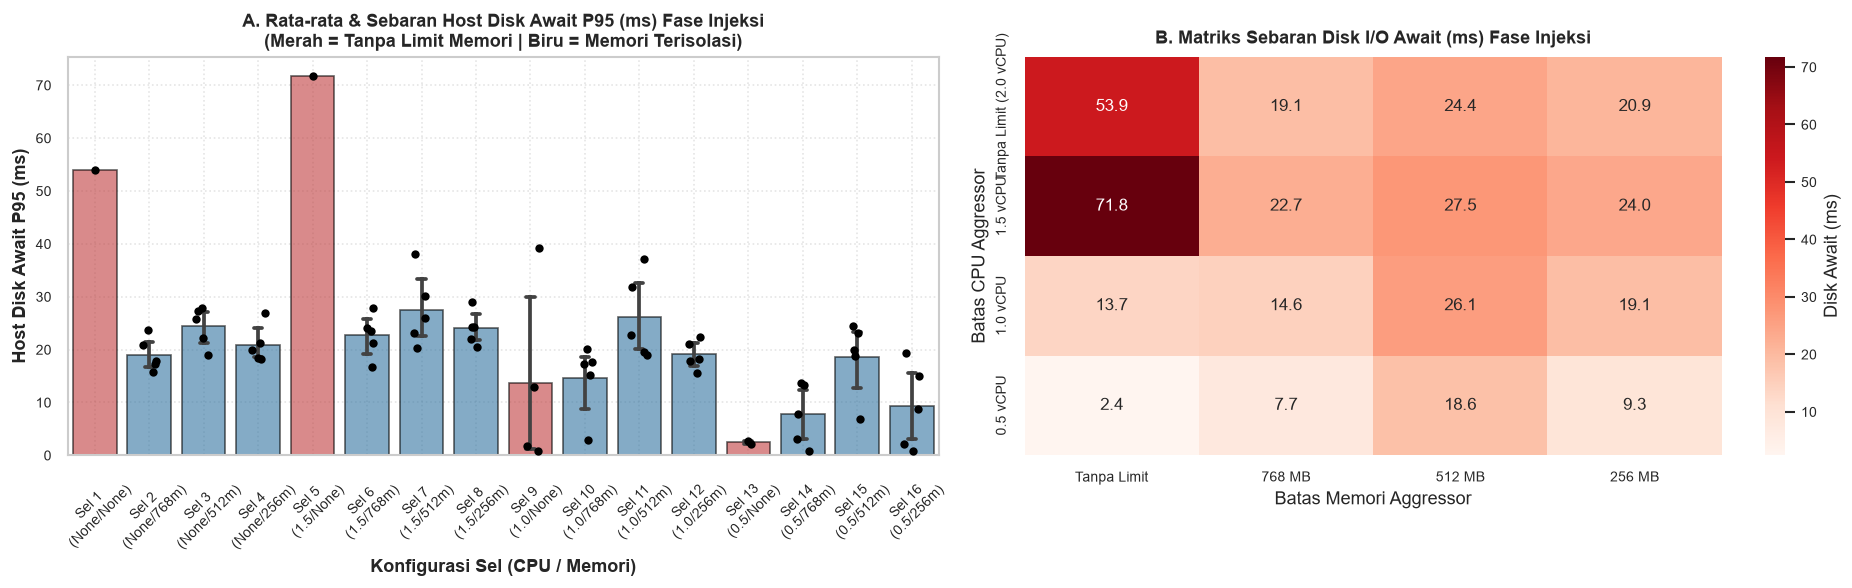

Catatan Data: Pada sel tanpa limit memori (Sel 1, 5, 9, 13), telemetri host hanya terekam pada sesi di mana host tidak mengalami pembekuan sistem,
sehingga jumlah sampel n_samples bervariasi (Sel 1: n=1, Sel 5: n=1, Sel 9: n=4, Sel 13: n=2).


In [65]:
# 5.1 Kuantifikasi & Visualisasi Efek Samping Silang pada Disk I/O (Schiavo et al., 2026)
disk_summary = df_sessions.groupby("cell_id").agg(
    cell_name=("cell_name", "first"),
    cfg_label=("cfg_label", "first"),
    cpus=("cpus", "first"),
    memory=("memory", "first"),
    n_samples=("host_disk_await_inj_ms", "count"),
    await_base_mean=("host_disk_await_base_ms", "mean"),
    await_inj_mean=("host_disk_await_inj_ms", "mean"),
    await_inj_std=("host_disk_await_inj_ms", "std"),
    tp_base_mean=("host_disk_tp_base_kbps", "mean"),
    tp_inj_mean=("host_disk_tp_inj_kbps", "mean"),
).reset_index()

print("Tabel Ringkasan Host Disk I/O Await (ms) & Throughput (kB/s) pada 16 Sel Konfigurasi:")
try:
    display(disk_summary[["cell_id", "cfg_label", "n_samples", "await_base_mean", "await_inj_mean", "tp_base_mean", "tp_inj_mean"]])
except NameError:
    print(disk_summary[["cell_id", "cfg_label", "n_samples", "await_base_mean", "await_inj_mean", "tp_base_mean", "tp_inj_mean"]].to_string())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Subplot 1: Bar Chart Disk Await (Fase Injeksi) dengan sebaran titik replikasi
sns.barplot(
    data=df_sessions,
    x="cfg_label",
    y="host_disk_await_inj_ms",
    palette=["#d62728" if m == "None" else "#1f77b4" for m in disk_summary["memory"]],
    alpha=0.6,
    edgecolor="black",
    ax=ax1,
    capsize=0.15,
)
sns.stripplot(
    data=df_sessions,
    x="cfg_label",
    y="host_disk_await_inj_ms",
    color="black",
    size=5,
    jitter=0.15,
    ax=ax1,
)
ax1.set_xlabel("Konfigurasi Sel (CPU / Memori)", weight="bold")
ax1.set_ylabel("Host Disk Await P95 (ms)", weight="bold")
ax1.set_title("A. Rata-rata & Sebaran Host Disk Await P95 (ms) Fase Injeksi\n(Merah = Tanpa Limit Memori | Biru = Memori Terisolasi)", weight="bold")
ax1.tick_params(axis="x", rotation=45)
ax1.grid(True, linestyle=":", alpha=0.5)

# Subplot 2: Heatmap Grid 4x4 Disk Await
grid_await_df = df_sessions.groupby(["cpus", "memory"])["host_disk_await_inj_ms"].mean().reset_index().rename(
    columns={"cpus": "Limit CPU", "memory": "Limit Memori", "host_disk_await_inj_ms": "await_mean"}
)
g_await = build_grid_matrix(grid_await_df, "await_mean")

sns.heatmap(g_await, annot=True, fmt=".1f", cmap="Reds", xticklabels=MEM_LABELS, yticklabels=CPU_LABELS, cbar_kws={"label": "Disk Await (ms)"}, ax=ax2)
ax2.set_title("B. Matriks Sebaran Disk I/O Await (ms) Fase Injeksi", fontsize=10.5, weight="bold", pad=8)
ax2.set_xlabel("Batas Memori Aggressor")
ax2.set_ylabel("Batas CPU Aggressor")

plt.tight_layout()
plt.show()
print("Catatan Data: Pada sel tanpa limit memori (Sel 1, 5, 9, 13), telemetri host hanya terekam pada sesi di mana host tidak mengalami pembekuan sistem,")
print("sehingga jumlah sampel n_samples bervariasi (Sel 1: n=1, Sel 5: n=1, Sel 9: n=4, Sel 13: n=2).")

Tabel Profil Waktu Reaksi OOM Killer pada Sel Terkena Intervensi:


,cell_id,cfg_label,memory,oom_count,oom_sec_mean,oom_delta_mean
0,2,Sel 2\n(None/768m),768m,5,21.810,11.810
1,3,Sel 3\n(None/512m),512m,5,22.606,12.606
2,4,Sel 4\n(None/256m),256m,5,13.002,3.002
3,6,Sel 6\n(1.5/768m),768m,5,18.602,8.602
4,7,Sel 7\n(1.5/512m),512m,5,15.406,5.406
5,8,Sel 8\n(1.5/256m),256m,5,13.004,3.004
6,9,Sel 9\n(1.0/None),None,2,42.445,32.445
7,10,Sel 10\n(1.0/768m),768m,5,24.258,14.258
8,11,Sel 11\n(1.0/512m),512m,5,19.004,9.004
9,12,Sel 12\n(1.0/256m),256m,5,13.408,3.408


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_33628\136144486.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=oom_plot_data, x="memory", y="oom_latency_from_attack_s", order=mem_order, palette="Oranges", width=0.4, ax=ax1)
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_33628\136144486.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax1.set_xticklabels(["256 MB (~3.0-5.0s)", "512 MB (~5.4-12.6s)", "768 MB (~8.6-17.8s)"])
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_33628\136144486.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_sessions, x="cpus", 

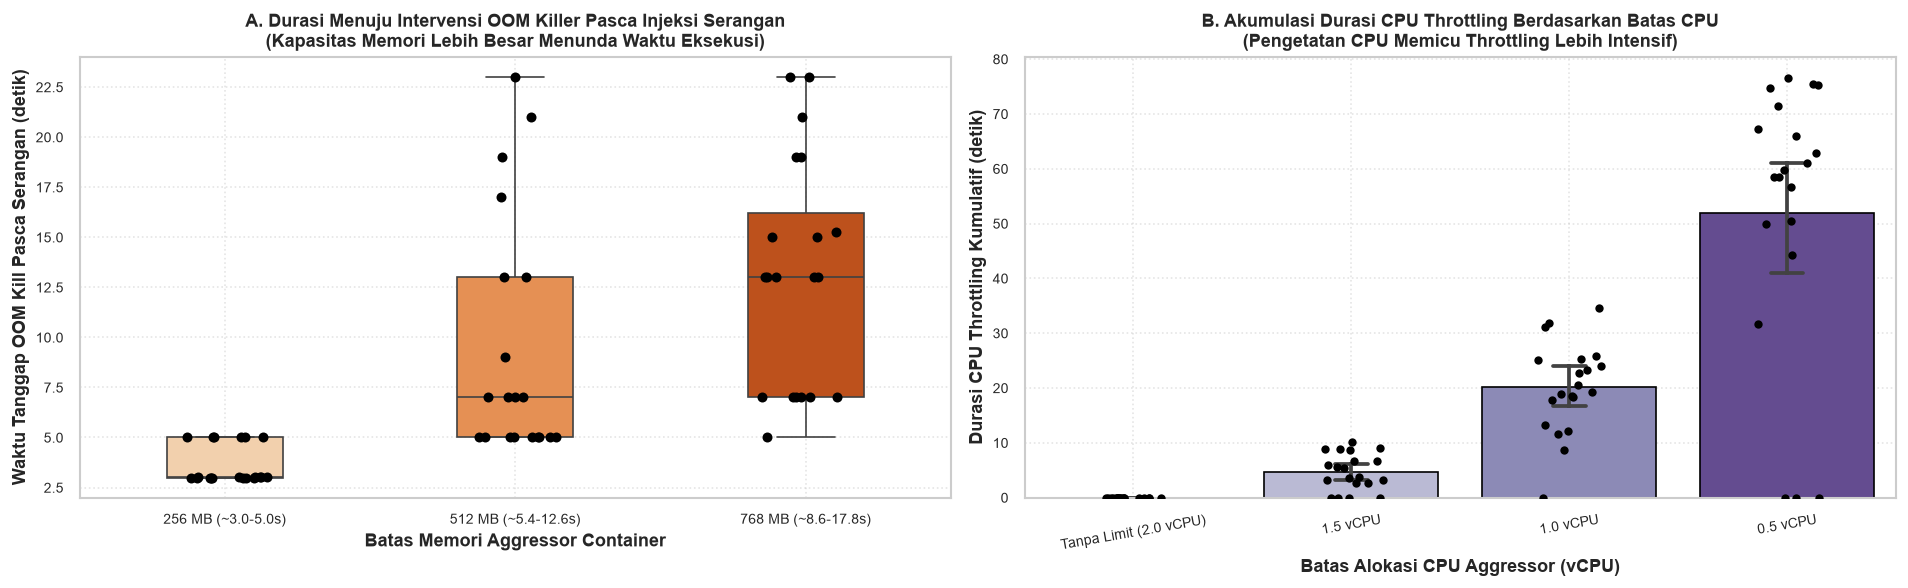

Temuan Kunci: Pada memori 256MB, OOM killer bereaksi sangat cepat (~3-5 detik) mematikan aggressor. Semakin longgar memori (768MB),
aggressor bertahan lebih lama di dalam container sebelum akhirnya mencapai batas memory.max.


In [66]:
# 5.2 Profil Waktu Nyata Intervensi Kernel (OOM Killer vs CPU Throttling)
oom_records = df_sessions[df_sessions["oom_killed"] == True].copy()
oom_records["oom_latency_from_attack_s"] = oom_records["oom_kill_second"] - 10.0

oom_stats = oom_records.groupby("cell_id").agg(
    cell_name=("cell_name", "first"),
    cfg_label=("cfg_label", "first"),
    memory=("memory", "first"),
    oom_count=("oom_killed", "count"),
    oom_sec_mean=("oom_kill_second", "mean"),
    oom_sec_std=("oom_kill_second", "std"),
    oom_delta_mean=("oom_latency_from_attack_s", "mean"),
).reset_index()

print("Tabel Profil Waktu Reaksi OOM Killer pada Sel Terkena Intervensi:")
try:
    display(oom_stats[["cell_id", "cfg_label", "memory", "oom_count", "oom_sec_mean", "oom_delta_mean"]])
except NameError:
    print(oom_stats[["cell_id", "cfg_label", "memory", "oom_count", "oom_sec_mean", "oom_delta_mean"]].to_string())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Subplot 1: Waktu Detik Picu OOM Killer Dikelompokkan Berdasarkan Limit Memori
mem_order = ["256m", "512m", "768m"]
oom_plot_data = oom_records[oom_records["memory"].isin(mem_order)].copy()

sns.boxplot(data=oom_plot_data, x="memory", y="oom_latency_from_attack_s", order=mem_order, palette="Oranges", width=0.4, ax=ax1)
sns.stripplot(data=oom_plot_data, x="memory", y="oom_latency_from_attack_s", order=mem_order, color="black", size=6, jitter=0.15, ax=ax1)
ax1.set_xlabel("Batas Memori Aggressor Container", weight="bold")
ax1.set_ylabel("Waktu Tanggap OOM Kill Pasca Serangan (detik)", weight="bold")
ax1.set_title("A. Durasi Menuju Intervensi OOM Killer Pasca Injeksi Serangan\n(Kapasitas Memori Lebih Besar Menunda Waktu Eksekusi)", weight="bold")
ax1.set_xticklabels(["256 MB (~3.0-5.0s)", "512 MB (~5.4-12.6s)", "768 MB (~8.6-17.8s)"])
ax1.grid(True, linestyle=":", alpha=0.5)

# Subplot 2: Akumulasi Durasi CPU Throttling Kumulatif Dikelompokkan Berdasarkan Limit CPU
sns.barplot(data=df_sessions, x="cpus", y="throttled_sec", order=CPU_LEVELS, palette="Purples", ax=ax2, capsize=0.15, edgecolor="black")
sns.stripplot(data=df_sessions, x="cpus", y="throttled_sec", order=CPU_LEVELS, color="black", size=5, jitter=0.15, ax=ax2)
ax2.set_xlabel("Batas Alokasi CPU Aggressor (vCPU)", weight="bold")
ax2.set_ylabel("Durasi CPU Throttling Kumulatif (detik)", weight="bold")
ax2.set_title("B. Akumulasi Durasi CPU Throttling Berdasarkan Batas CPU\n(Pengetatan CPU Memicu Throttling Lebih Intensif)", weight="bold")
ax2.set_xticks(range(len(CPU_LEVELS)))
ax2.set_xticklabels(CPU_LABELS, rotation=10)
ax2.grid(True, linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()
print("Temuan Kunci: Pada memori 256MB, OOM killer bereaksi sangat cepat (~3-5 detik) mematikan aggressor. Semakin longgar memori (768MB),")
print("aggressor bertahan lebih lama di dalam container sebelum akhirnya mencapai batas memory.max.")

Baseline Flood Requests Sel 1 Kontrol: 741.0 requests.
Tabel Kuantifikasi Peredaman Beban Aggressor:


,cell_id,cfg_label,flood_req_mean,containment_efficiency_pct,success_req_mean,failed_req_mean
0,1,Sel 1\n(None/None),741.0,0.000000,521.8,219.2
1,2,Sel 2\n(None/768m),715.8,3.400810,500.0,215.8
2,3,Sel 3\n(None/512m),577.0,22.132254,273.6,303.4
3,4,Sel 4\n(None/256m),421.2,43.157895,40.0,381.2
4,5,Sel 5\n(1.5/None),680.8,8.124157,484.4,196.4
5,6,Sel 6\n(1.5/768m),769.0,-3.778677,593.0,176.0
6,7,Sel 7\n(1.5/512m),541.8,26.882591,234.6,307.2
7,8,Sel 8\n(1.5/256m),378.8,48.879892,43.2,335.6
8,9,Sel 9\n(1.0/None),625.2,15.627530,454.0,171.2
9,10,Sel 10\n(1.0/768m),701.2,5.371120,517.0,184.2


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_33628\3731635096.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_sessions, x="cpus", y="aggressor_flood_requests", order=CPU_LEVELS, palette="crest", ax=ax1, capsize=0.15, edgecolor="black")


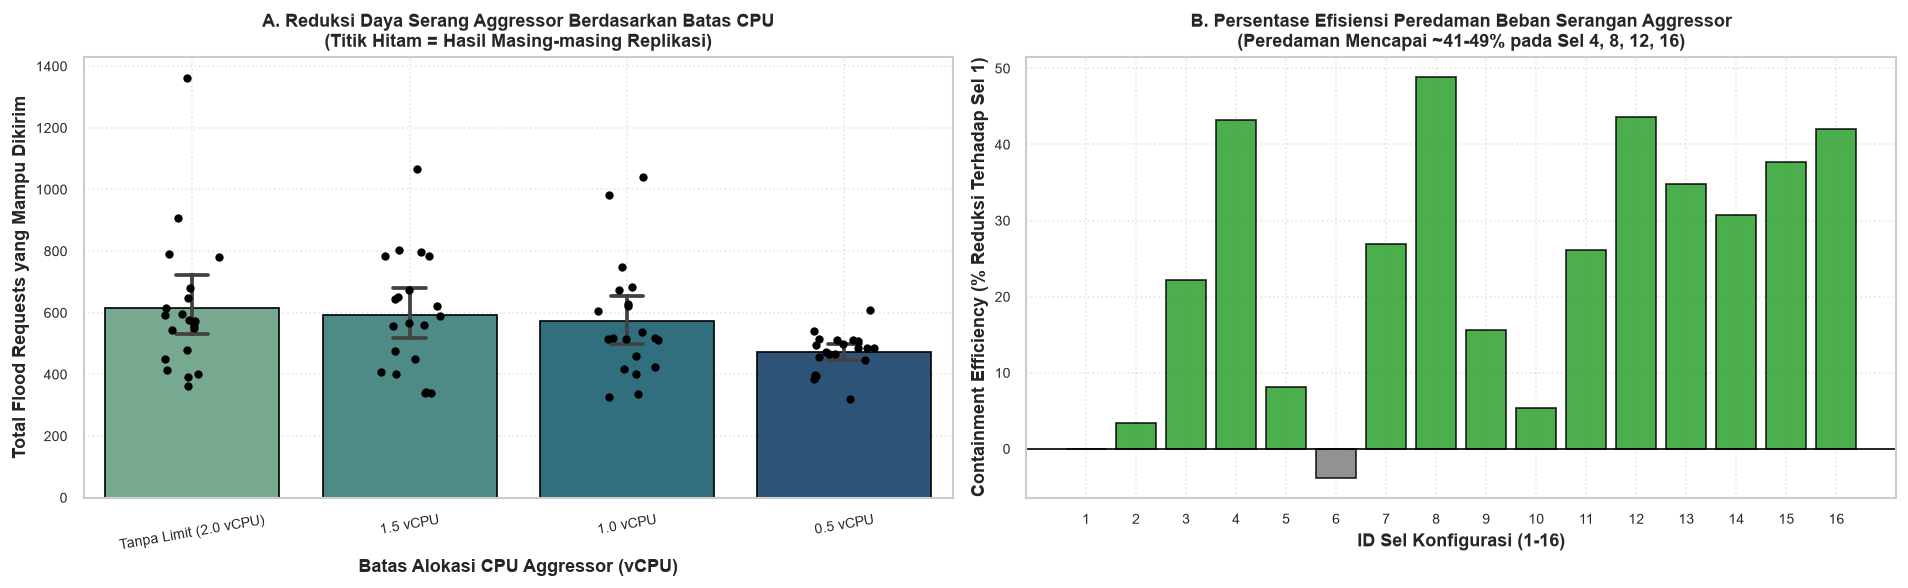

Cara Baca: Pengetatan alokasi CPU dan memori secara simultan mampu memangkas volume serangan flood hingga mendekati separuhnya (48.88%).


In [67]:
# 5.3 Efisiensi Peredaman Beban Aggressor Container (Containment Efficiency)
base_aggr_req = df_sessions[df_sessions["cell_id"] == 1]["aggressor_flood_requests"].mean()

aggr_summary = df_sessions.groupby("cell_id").agg(
    cell_name=("cell_name", "first"),
    cfg_label=("cfg_label", "first"),
    cpus=("cpus", "first"),
    memory=("memory", "first"),
    flood_req_mean=("aggressor_flood_requests", "mean"),
    flood_req_std=("aggressor_flood_requests", "std"),
    success_req_mean=("aggressor_success_requests", "mean"),
    failed_req_mean=("aggressor_failed_requests", "mean"),
).reset_index()

aggr_summary["containment_efficiency_pct"] = ((base_aggr_req - aggr_summary["flood_req_mean"]) / base_aggr_req) * 100.0

print(f"Baseline Flood Requests Sel 1 Kontrol: {base_aggr_req:.1f} requests.")
print("Tabel Kuantifikasi Peredaman Beban Aggressor:")
try:
    display(aggr_summary[["cell_id", "cfg_label", "flood_req_mean", "containment_efficiency_pct", "success_req_mean", "failed_req_mean"]])
except NameError:
    print(aggr_summary[["cell_id", "cfg_label", "flood_req_mean", "containment_efficiency_pct", "success_req_mean", "failed_req_mean"]].to_string())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Subplot 1: Flood Requests Aggressor vs Batas CPU (Bar + Stripplot)
sns.barplot(data=df_sessions, x="cpus", y="aggressor_flood_requests", order=CPU_LEVELS, palette="crest", ax=ax1, capsize=0.15, edgecolor="black")
sns.stripplot(data=df_sessions, x="cpus", y="aggressor_flood_requests", order=CPU_LEVELS, color="black", size=5, jitter=0.15, ax=ax1)
ax1.set_xlabel("Batas Alokasi CPU Aggressor (vCPU)", weight="bold")
ax1.set_ylabel("Total Flood Requests yang Mampu Dikirim", weight="bold")
ax1.set_title("A. Reduksi Daya Serang Aggressor Berdasarkan Batas CPU\n(Titik Hitam = Hasil Masing-masing Replikasi)", weight="bold")
ax1.set_xticks(range(len(CPU_LEVELS)))
ax1.set_xticklabels(CPU_LABELS, rotation=10)
ax1.grid(True, linestyle=":", alpha=0.5)

# Subplot 2: Efisiensi Peredaman Beban (%) di Seluruh 16 Sel
colors_cont = ["#2ca02c" if val > 0 else "#7f7f7f" for val in aggr_summary["containment_efficiency_pct"]]
ax2.bar(aggr_summary["cell_id"], aggr_summary["containment_efficiency_pct"], color=colors_cont, alpha=0.85, edgecolor="black")
ax2.axhline(y=0.0, color="black", linestyle="-", linewidth=1.0) # Garis basis Sel 1
ax2.set_xlabel("ID Sel Konfigurasi (1-16)", weight="bold")
ax2.set_ylabel("Containment Efficiency (% Reduksi Terhadap Sel 1)", weight="bold")
ax2.set_title("B. Persentase Efisiensi Peredaman Beban Serangan Aggressor\n(Peredaman Mencapai ~41-49% pada Sel 4, 8, 12, 16)", weight="bold")
ax2.set_xticks(range(1, 17))
ax2.grid(True, linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()
print("Cara Baca: Pengetatan alokasi CPU dan memori secara simultan mampu memangkas volume serangan flood hingga mendekati separuhnya (48.88%).")